# Importando Bibliotecas

In [1]:
import os
import sys

sys.path.append("/home/sophia.ozorio/storage/python-ml/projeto_ML_python")

# Carregamento de dados
from joblib import load, dump

# Processamento de dados
import numpy as np
import pandas as pd

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Funções de clustering
from dev.script.src.modelos.clustering import Clustering

# Importando Dados

In [2]:
# Pastas com o split 
caminho_dir = "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/split_dataset/"
caminho_res = "/home/sophia.ozorio/storage/python-ml/projeto_ML_python/dev/script/results/clusterizacao/"
os.makedirs(caminho_res, exist_ok=True)

# Verificando os arquivos no diretório do split
os.listdir(caminho_dir)

['y_ataxia_train_ready.csv',
 'df_valid_resultados_regression',
 'X_train_ready.csv',
 'y_idade_valid_ready.csv',
 'y_idade_test_ready.csv',
 'X_valid_ready.csv',
 'df_train_resultados_regression',
 'X_test_ready.csv',
 'y_ataxia_test_ready.csv',
 'df_test_resultados_regression',
 'y_ataxia_valid_ready.csv',
 'y_idade_train_ready.csv']

In [3]:
# --- TREINO ---
X_train = pd.read_csv(f"{caminho_dir}X_train_ready.csv")
y_idade_train = pd.read_csv(f"{caminho_dir}y_idade_train_ready.csv")
X_train["idade_inicio_sintomas"] = y_idade_train.values  
df_train = pd.concat(
    [
        X_train,
        pd.read_csv(f"{caminho_dir}y_ataxia_train_ready.csv"),
    ],
    axis=1,
)

In [4]:
# --- VALIDAÇÃO ---
X_valid = pd.read_csv(f"{caminho_dir}X_valid_ready.csv")
y_idade_valid = pd.read_csv(f"{caminho_dir}y_idade_valid_ready.csv")
X_valid["idade_inicio_sintomas"] = y_idade_valid.values  # ou y_idade_valid['idade_inicio_sintomas']

df_valid = pd.concat(
    [
        X_valid,
        pd.read_csv(f"{caminho_dir}y_ataxia_valid_ready.csv"),
    ],
    axis=1,
)

In [5]:
# --- TESTE ---
X_test = pd.read_csv(f"{caminho_dir}X_test_ready.csv")
y_idade_test = pd.read_csv(f"{caminho_dir}y_idade_test_ready.csv")
X_test["idade_inicio_sintomas"] = y_idade_test.values  # ou y_idade_test['idade_inicio_sintomas']

df_test = pd.concat(
    [
        X_test,
        pd.read_csv(f"{caminho_dir}y_ataxia_test_ready.csv"),
    ],
    axis=1,
)

print("Treino head com idade:")
print(df_train.head())

Treino head com idade:
   tipo_variante_frameshift  tipo_variante_missense  tipo_variante_nonsense  \
0                       0.0                     1.0                     0.0   
1                       0.0                     1.0                     0.0   
2                       1.0                     0.0                     0.0   
3                       1.0                     0.0                     0.0   
4                       0.0                     1.0                     0.0   

   ancestralidade_AFR  ancestralidade_AMR  ancestralidade_Desconhecido  \
0                 0.0                 0.0                          0.0   
1                 0.0                 0.0                          0.0   
2                 0.0                 1.0                          0.0   
3                 0.0                 0.0                          0.0   
4                 0.0                 1.0                          0.0   

   ancestralidade_EAS  ancestralidade_EUR  ancestralidade

# Definindo as variáveis para o clustering

In [6]:
# O clustering é feito em pares de variáveis contínuas (bivariadas). As demais colunas são one-hot/binárias e não entram no clustering.
colunas_num = [
    "cadd_phred",
    "conservacao_phylop",
    "profundidade_leitura",
    "gnomad_af_log",
    "idade_inicio_sintomas",
]

# Combinações analisadas em detalhe. 
bivariadas = [
    ["cadd_phred", "gnomad_af_log"],
    ["cadd_phred", "conservacao_phylop"],
    ["conservacao_phylop", "gnomad_af_log"],
    ["idade_inicio_sintomas", "cadd_phred"],
    ["idade_inicio_sintomas", "conservacao_phylop"],
    ["idade_inicio_sintomas", "gnomad_af_log"]
]
for k, par in enumerate(bivariadas):
    print(k, "->", par)

0 -> ['cadd_phred', 'gnomad_af_log']
1 -> ['cadd_phred', 'conservacao_phylop']
2 -> ['conservacao_phylop', 'gnomad_af_log']
3 -> ['idade_inicio_sintomas', 'cadd_phred']
4 -> ['idade_inicio_sintomas', 'conservacao_phylop']
5 -> ['idade_inicio_sintomas', 'gnomad_af_log']


# Validação cruzada e busca de hiperparâmetros

## K-means

### Treino

In [7]:
# Definindo um objeto de clustering com os dados de treino
nome_modelo = "kmeans"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 0, 1, 1, 0], dtype=int32)

In [8]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de variáveis
data = {}
for i in colunas_num:
    for j in colunas_num:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
cadd_phred_conservacao_phylop,0.454,862.028,0.824,0.121,0.108
cadd_phred_profundidade_leitura,0.349,469.582,0.919,0.087,0.082
cadd_phred_gnomad_af_log,0.500,1143.762,0.735,0.129,0.117
cadd_phred_idade_inicio_sintomas,0.445,828.870,0.837,0.175,0.159
conservacao_phylop_cadd_phred,0.454,862.028,0.824,0.121,0.108
conservacao_phylop_profundidade_leitura,0.345,459.187,0.926,0.020,0.019
conservacao_phylop_gnomad_af_log,0.448,811.103,0.854,0.107,0.095
conservacao_phylop_idade_inicio_sintomas,0.384,569.555,0.999,0.138,0.125
profundidade_leitura_cadd_phred,0.349,469.582,0.919,0.087,0.082
profundidade_leitura_conservacao_phylop,0.345,459.187,0.926,0.020,0.019


In [9]:
'''Selecionando as melhores combinações de variáveis com base nas métricas de avaliação de clustering 
(maior Silhouette, Calinski-Harabasz, Adjusted Rand e Adjusted Mutual Info; menor Davies-Bouldin) '''

display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nlargest(1))
display(df_metricas["Davies Bouldin"].nsmallest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

cadd_phred_gnomad_af_log    0.5
Name: Silhouette, dtype: float64

cadd_phred_gnomad_af_log    1143.762
Name: Calinski Harabasz, dtype: float64

cadd_phred_gnomad_af_log    0.735
Name: Davies Bouldin, dtype: float64

cadd_phred_idade_inicio_sintomas    0.175
Name: Adjusted Rand, dtype: float64

cadd_phred_idade_inicio_sintomas    0.159
Name: Adjusted Mutual Info, dtype: float64

=== CONJUNTO DE TREINO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.5050

Silhouette Score -> 0.5
Calinski Harabasz Score -> 1143.762
Davies Bouldin Score -> 0.735
Adjusted Rand Score -> 0.129
Adjusted Mutual Info Score -> 0.117


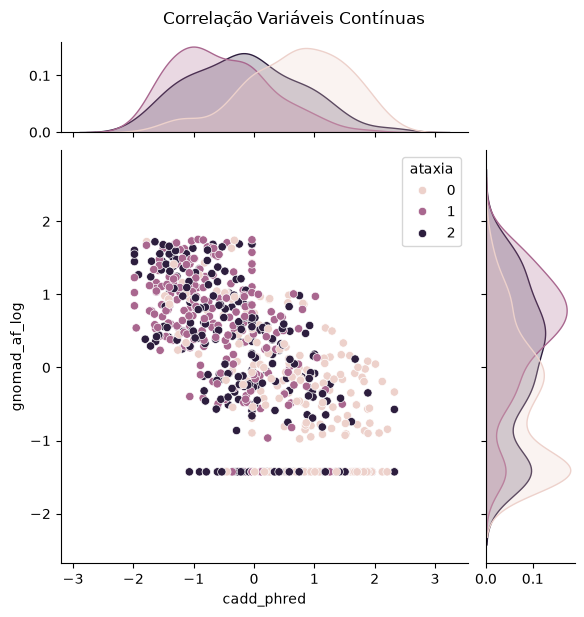

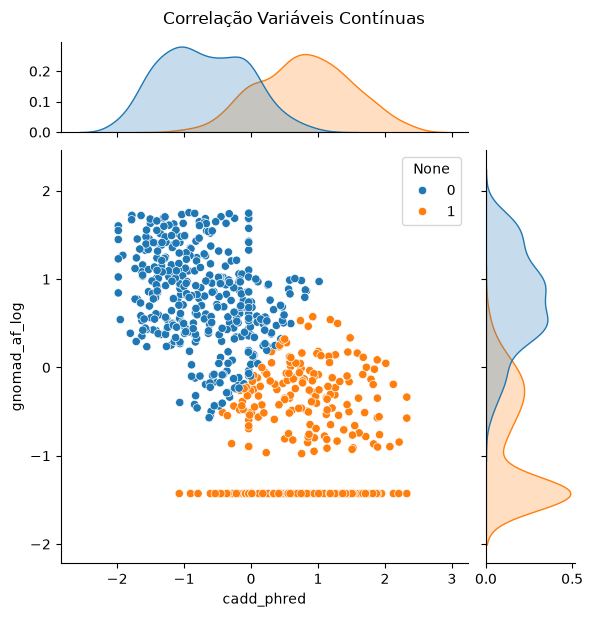

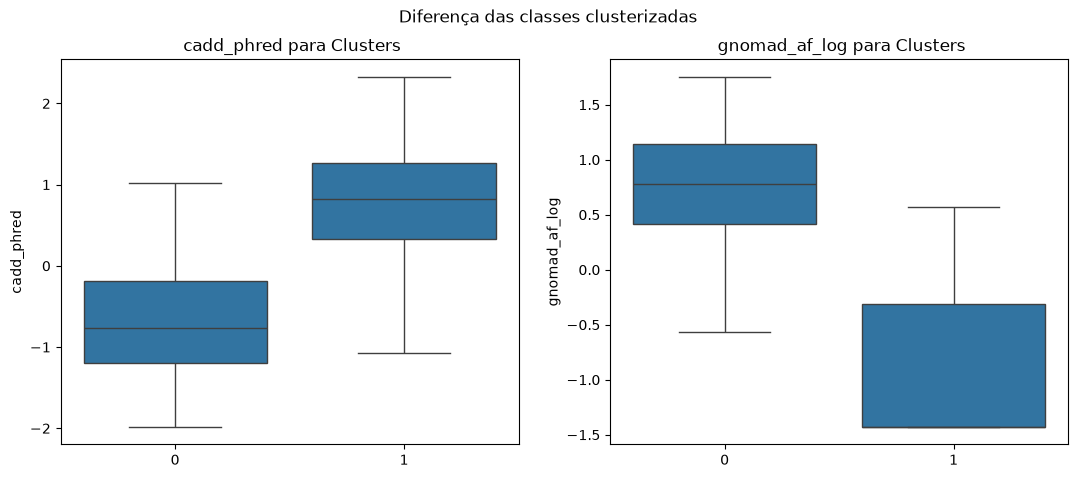


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.4618

Silhouette Score -> 0.454
Calinski Harabasz Score -> 862.028
Davies Bouldin Score -> 0.824
Adjusted Rand Score -> 0.121
Adjusted Mutual Info Score -> 0.108


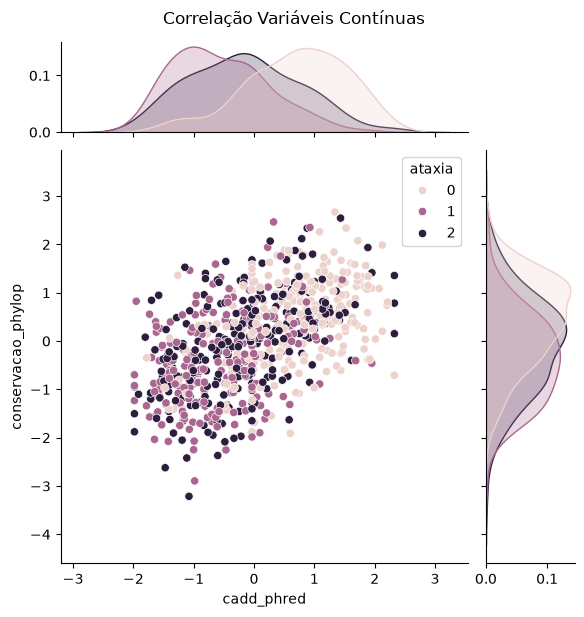

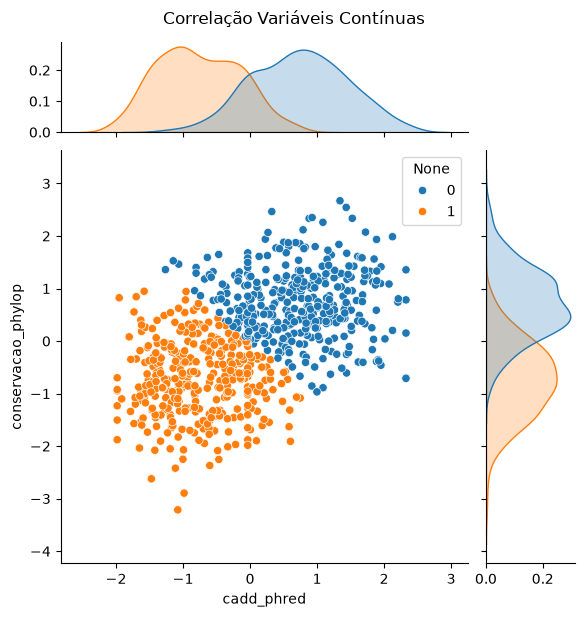

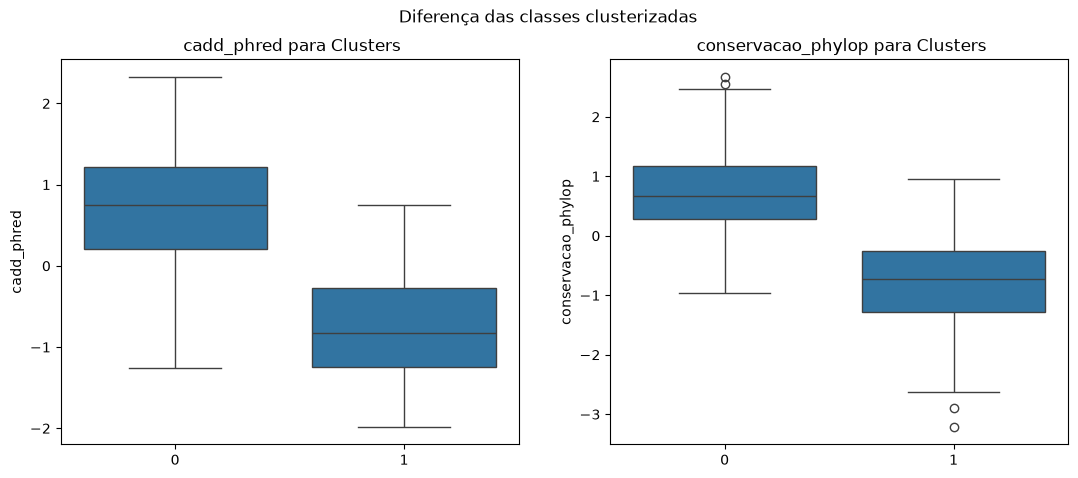


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.4488

Silhouette Score -> 0.448
Calinski Harabasz Score -> 811.103
Davies Bouldin Score -> 0.854
Adjusted Rand Score -> 0.107
Adjusted Mutual Info Score -> 0.095


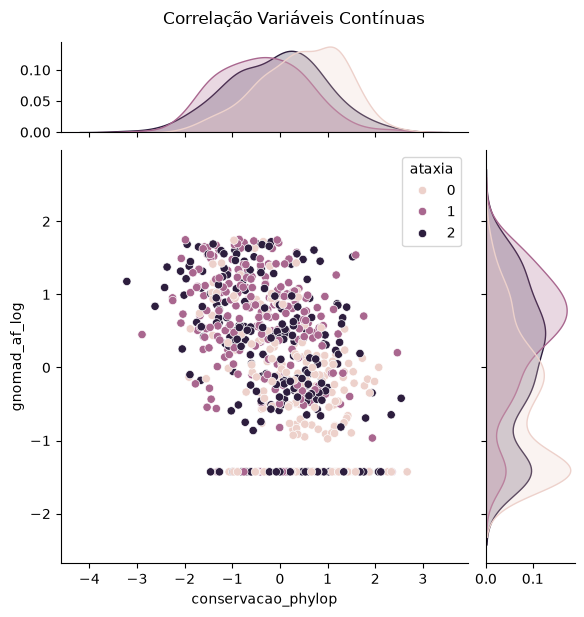

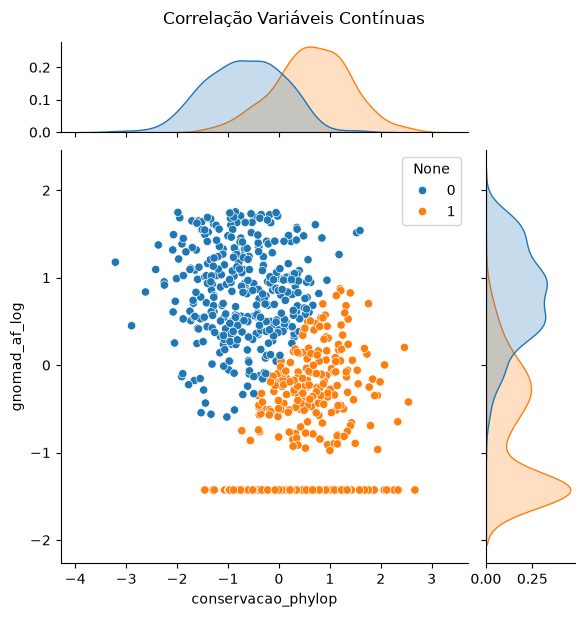

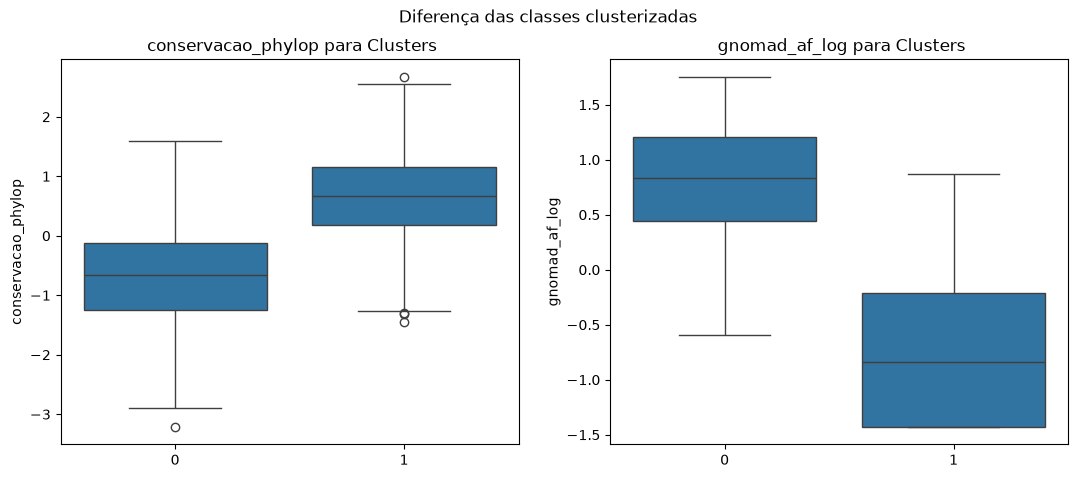


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'random', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.4514

Silhouette Score -> 0.445
Calinski Harabasz Score -> 828.87
Davies Bouldin Score -> 0.837
Adjusted Rand Score -> 0.175
Adjusted Mutual Info Score -> 0.159


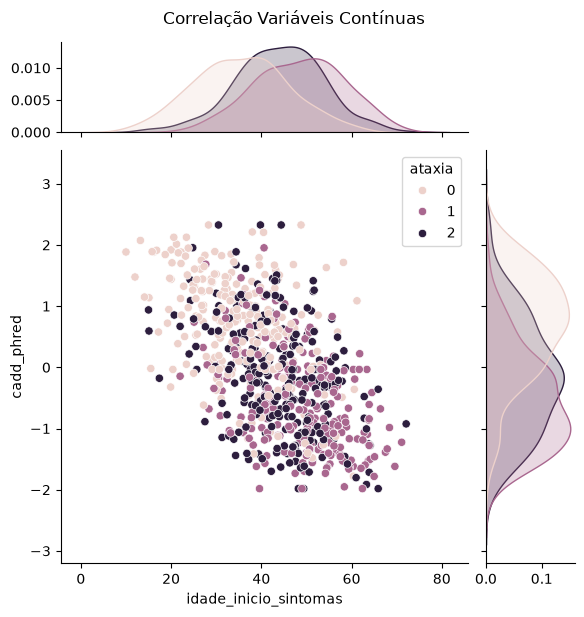

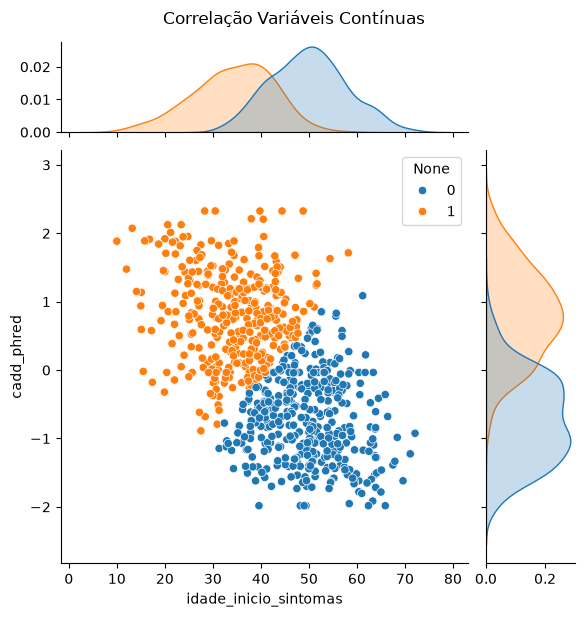

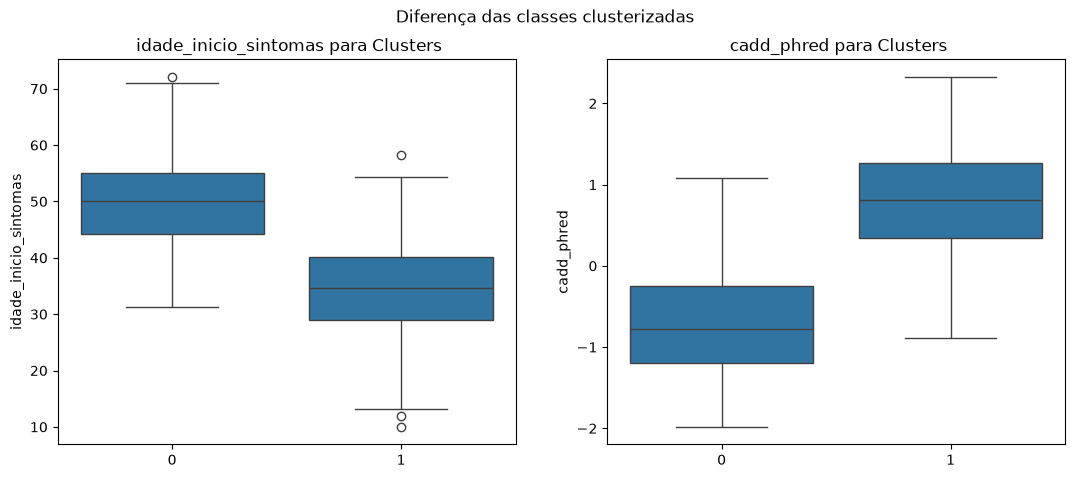


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.3881

Silhouette Score -> 0.384
Calinski Harabasz Score -> 569.555
Davies Bouldin Score -> 0.999
Adjusted Rand Score -> 0.138
Adjusted Mutual Info Score -> 0.125


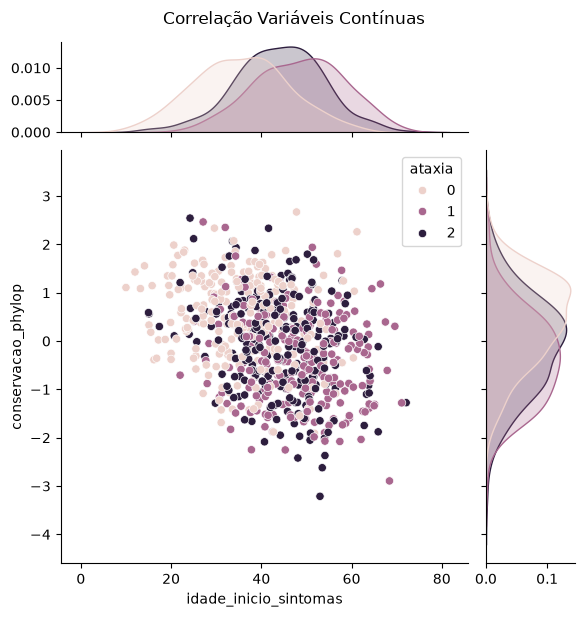

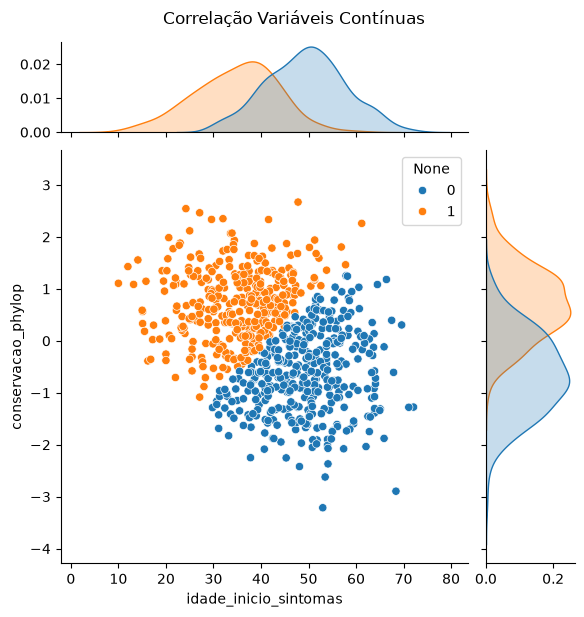

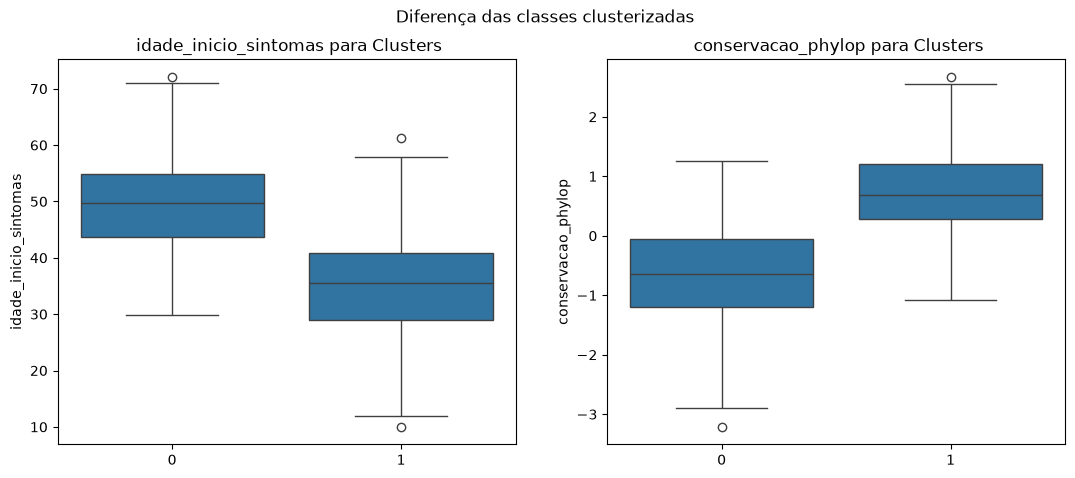


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.4236

Silhouette Score -> 0.421
Calinski Harabasz Score -> 670.593
Davies Bouldin Score -> 0.935
Adjusted Rand Score -> 0.146
Adjusted Mutual Info Score -> 0.132


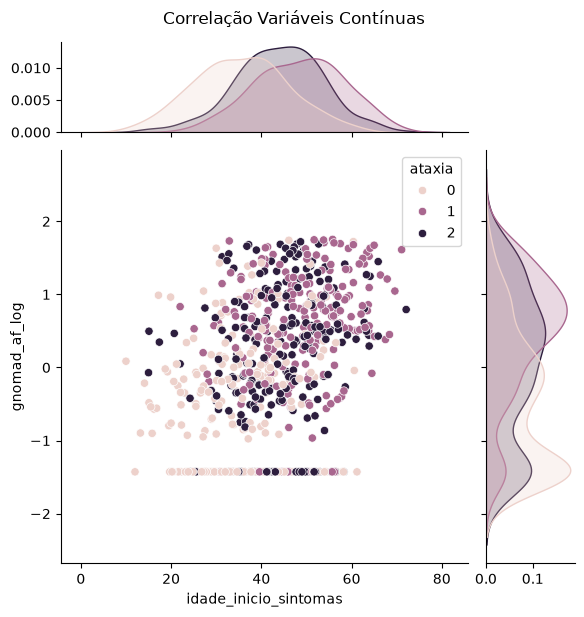

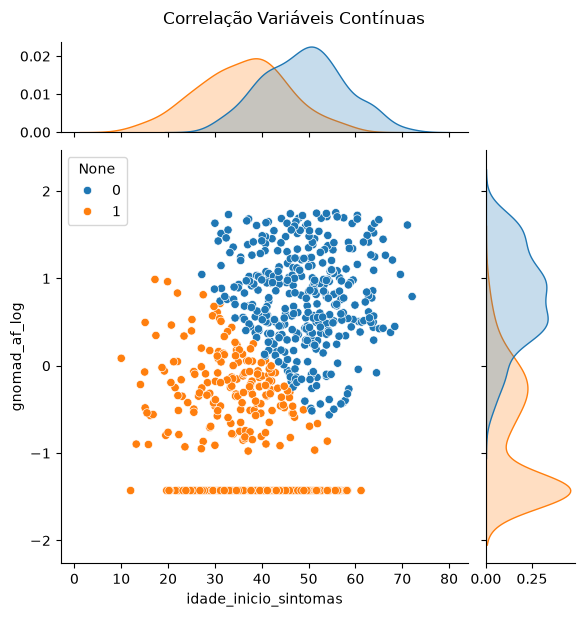

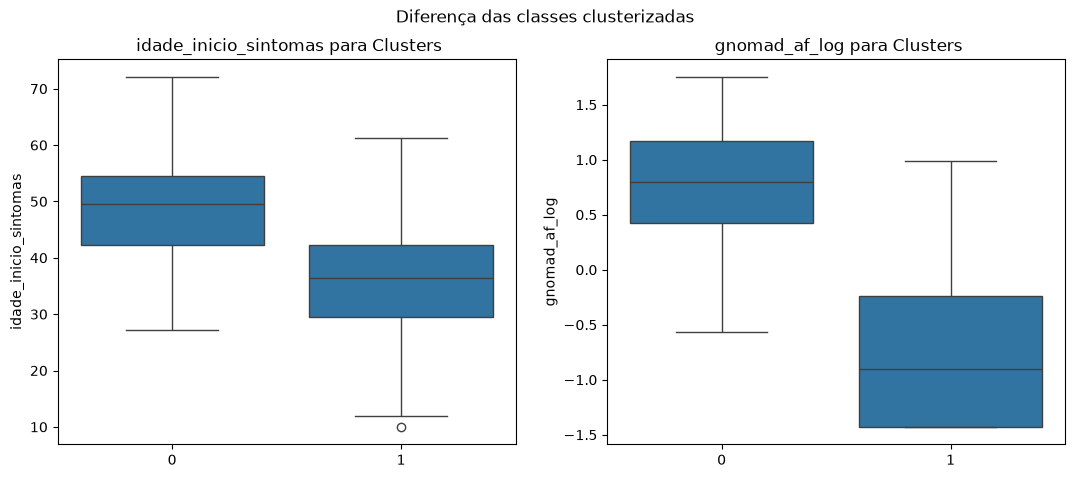

In [10]:
# Executando a validação cruzada para todas as combinações bivariadas cadastradas 
print("=== CONJUNTO DE TREINO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_train, modelo=nome_modelo)
    cluster.cross_validation()

In [11]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.5,1143.762,0.735,0.129,0.117
1,0.5,1143.762,0.735,0.129,0.117
2,0.5,1143.762,0.735,0.129,0.117
3,0.5,1143.762,0.735,0.129,0.117
4,0.5,1143.762,0.735,0.129,0.117


In [12]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,50.0,50.000,50.000,5.000000e+01,50.000
mean,0.5,1143.762,0.735,1.290000e-01,0.117
std,0.0,0.000,0.000,2.803737e-17,0.000
min,0.5,1143.762,0.735,1.290000e-01,0.117
25%,0.5,1143.762,0.735,1.290000e-01,0.117
50%,0.5,1143.762,0.735,1.290000e-01,0.117
75%,0.5,1143.762,0.735,1.290000e-01,0.117
max,0.5,1143.762,0.735,1.290000e-01,0.117


### Validação

In [13]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_kmeans = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_kmeans.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.53,359.117,0.682,0.124,0.114
1,0.53,359.117,0.682,0.124,0.114
2,0.53,359.117,0.682,0.124,0.114
3,0.53,359.117,0.682,0.124,0.114
4,0.53,359.117,0.682,0.124,0.114


In [14]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti_valid_kmeans.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,5.000000e+01,5.000000e+01,5.000000e+01,5.000000e+01,50.000
mean,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114
std,1.121495e-16,5.742052e-14,1.121495e-16,1.401868e-17,0.000
min,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114
25%,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114
50%,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114
75%,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114
max,5.300000e-01,3.591170e+02,6.820000e-01,1.240000e-01,0.114



=== CONJUNTO DE VALIDAÇÃO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.5304

Silhouette Score -> 0.53
Calinski Harabasz Score -> 359.117
Davies Bouldin Score -> 0.682
Adjusted Rand Score -> 0.124
Adjusted Mutual Info Score -> 0.114


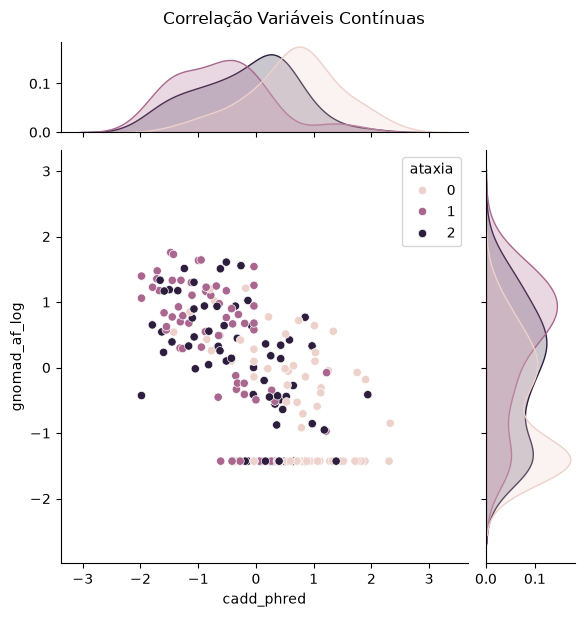

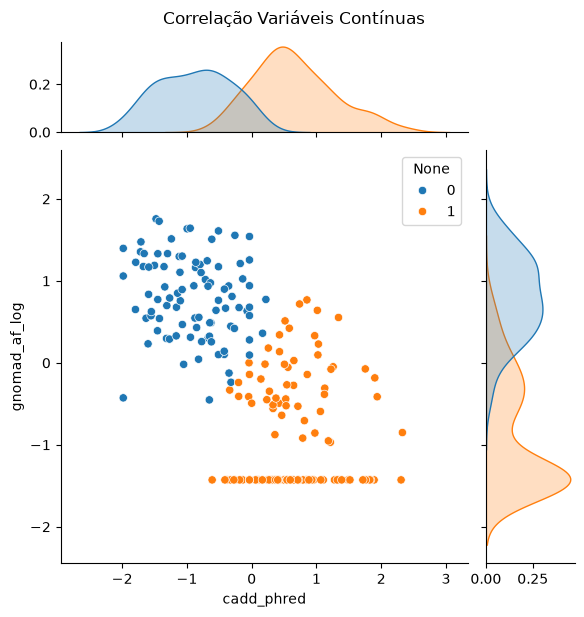

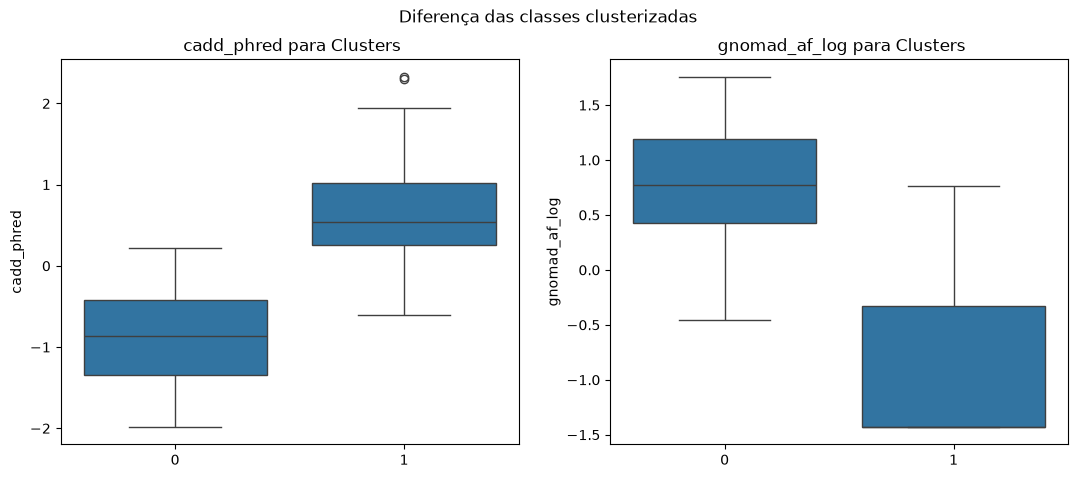


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.4645

Silhouette Score -> 0.456
Calinski Harabasz Score -> 252.298
Davies Bouldin Score -> 0.819
Adjusted Rand Score -> 0.147
Adjusted Mutual Info Score -> 0.135


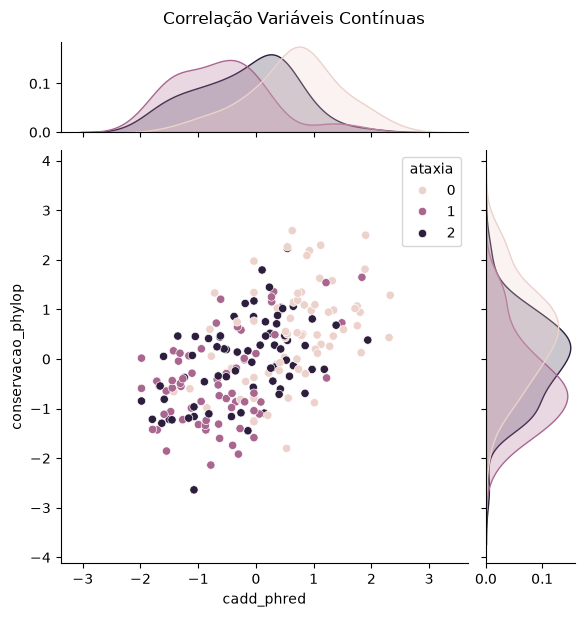

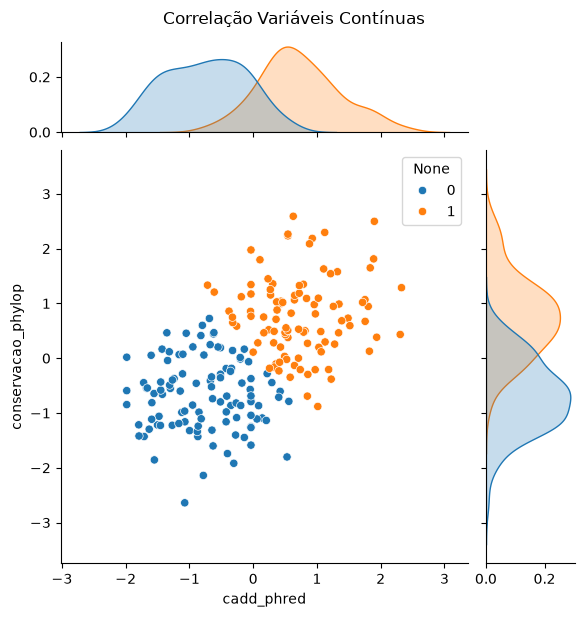

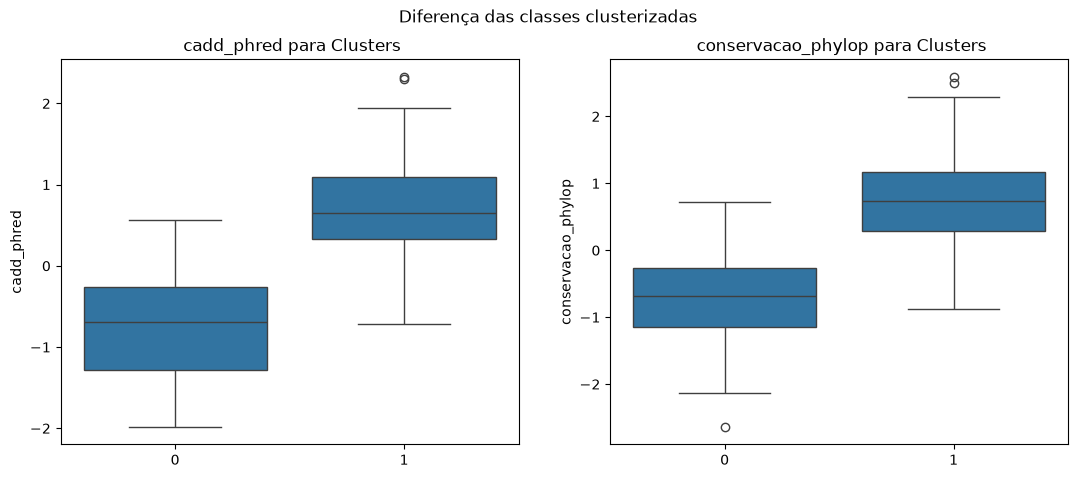


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.4941

Silhouette Score -> 0.493
Calinski Harabasz Score -> 279.453
Davies Bouldin Score -> 0.763
Adjusted Rand Score -> 0.074
Adjusted Mutual Info Score -> 0.066


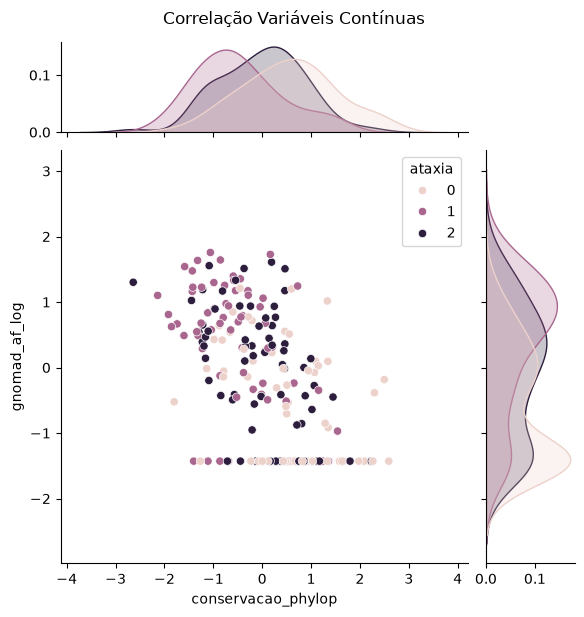

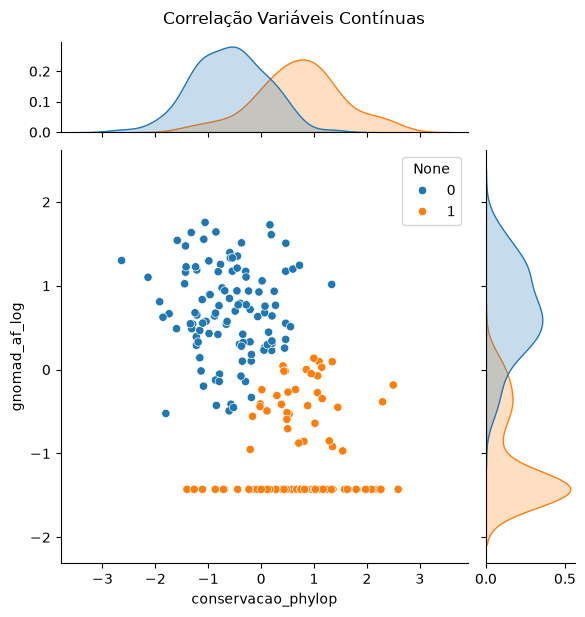

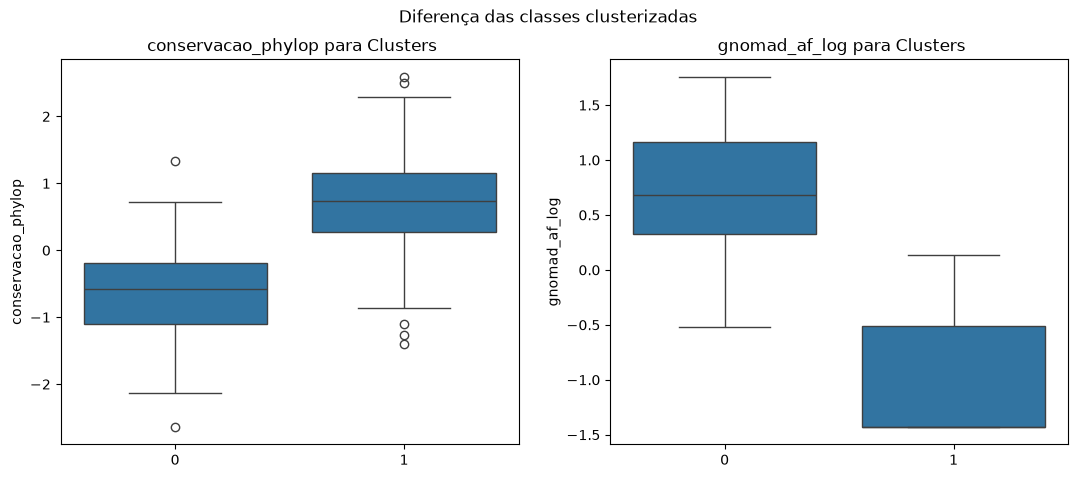


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 20}
Silhouette Score Médio (CV): 0.4636

Silhouette Score -> 0.439
Calinski Harabasz Score -> 233.92
Davies Bouldin Score -> 0.829
Adjusted Rand Score -> 0.179
Adjusted Mutual Info Score -> 0.169


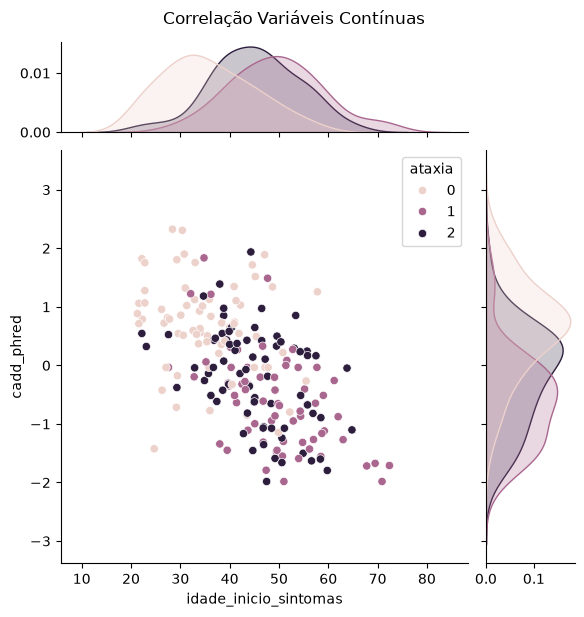

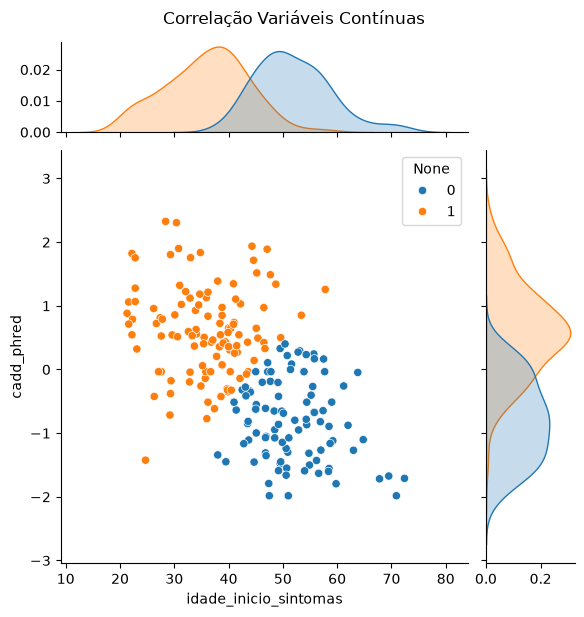

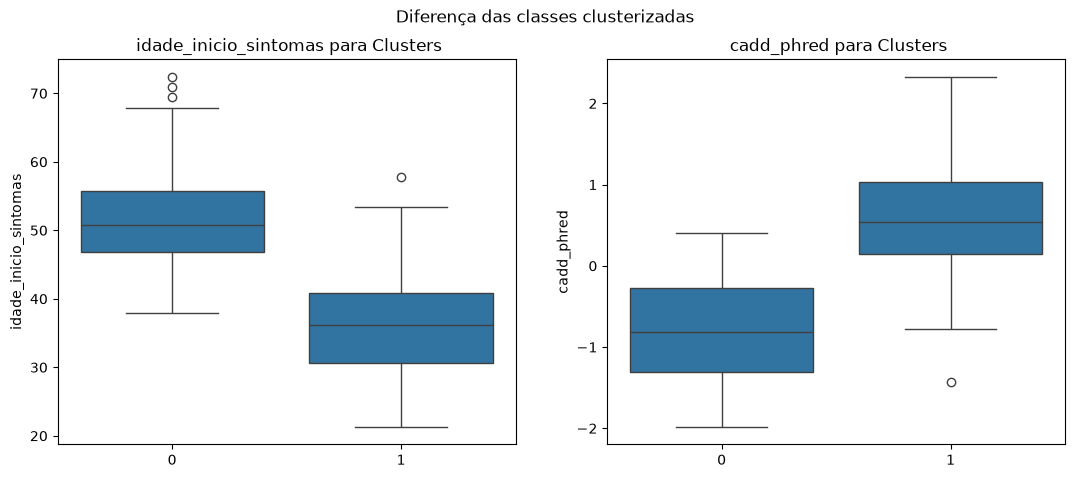


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.4184

Silhouette Score -> 0.39
Calinski Harabasz Score -> 171.823
Davies Bouldin Score -> 0.963
Adjusted Rand Score -> 0.135
Adjusted Mutual Info Score -> 0.124


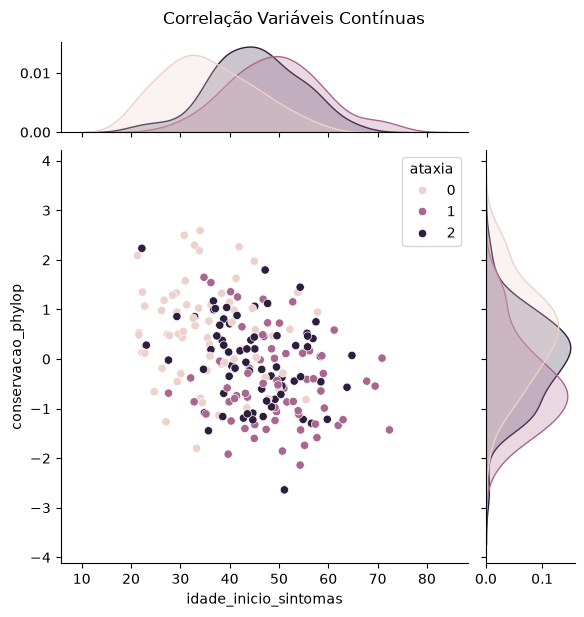

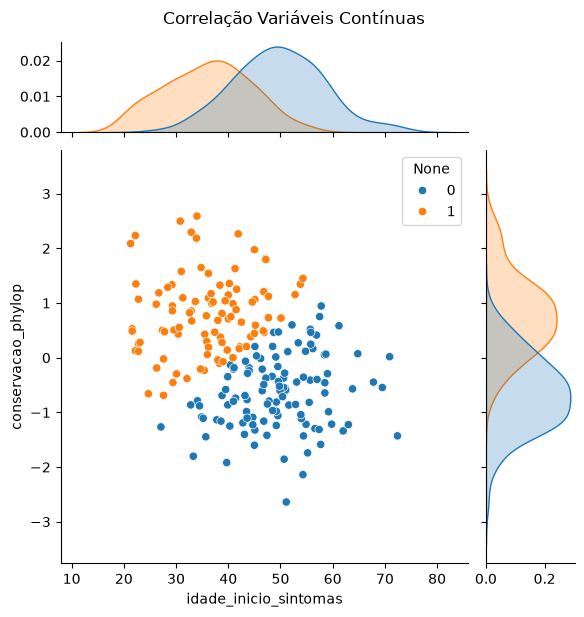

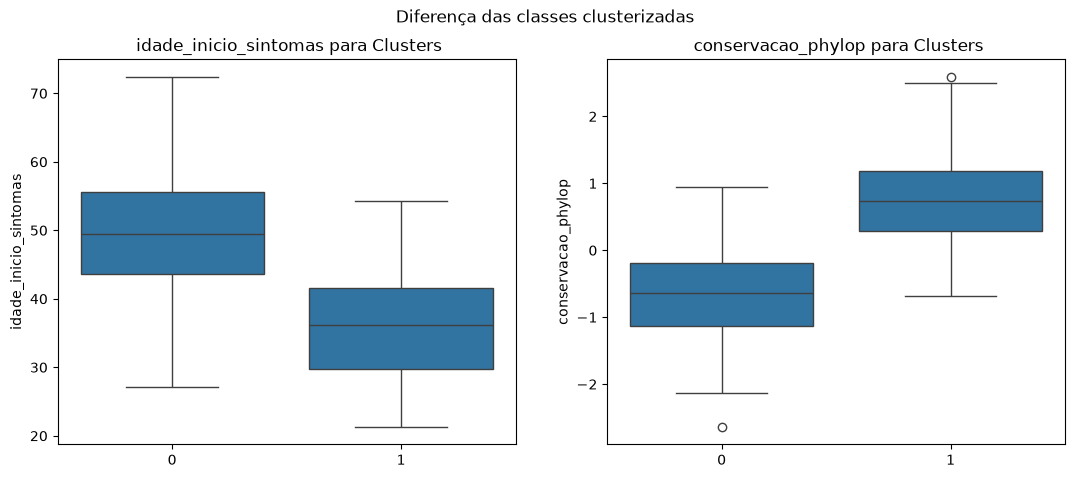


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'init': 'k-means++', 'n_init': 10}
Silhouette Score Médio (CV): 0.4619

Silhouette Score -> 0.442
Calinski Harabasz Score -> 214.936
Davies Bouldin Score -> 0.872
Adjusted Rand Score -> 0.107
Adjusted Mutual Info Score -> 0.096


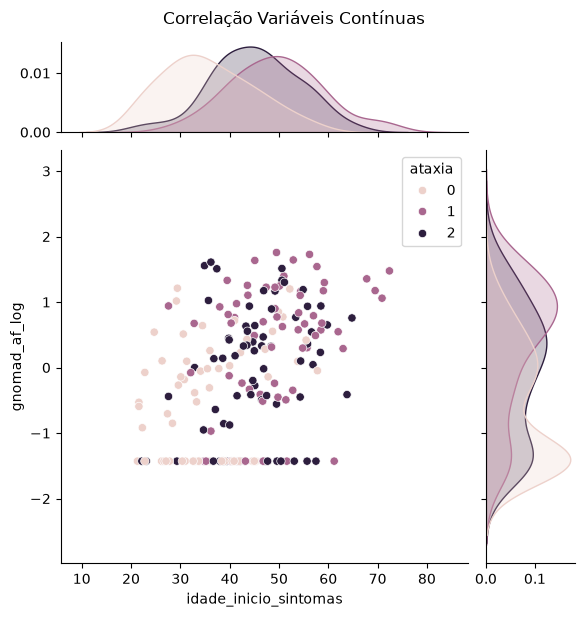

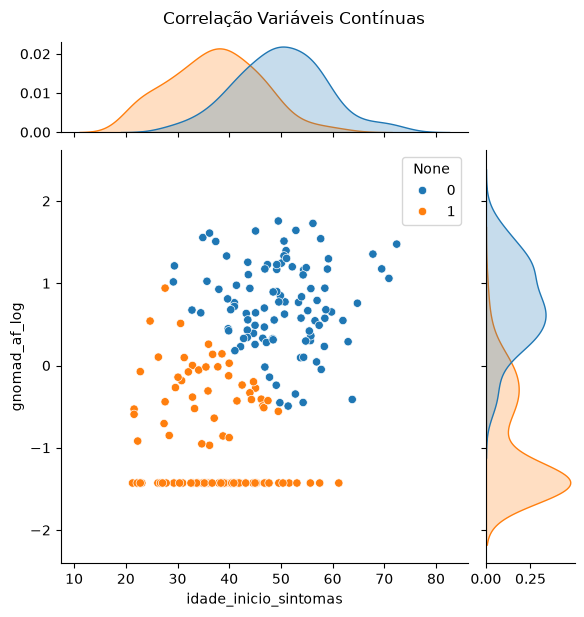

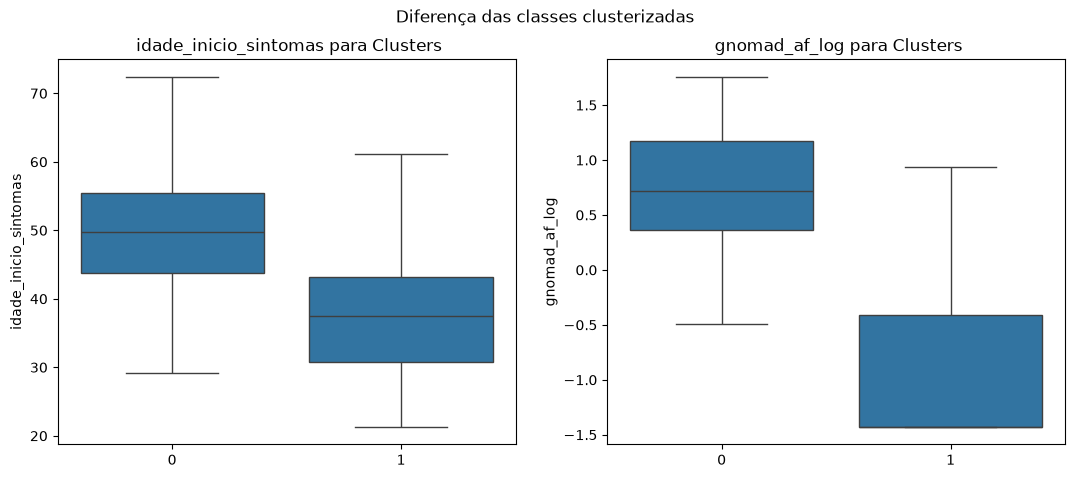

In [15]:
# Analisando os clusters
print("\n=== CONJUNTO DE VALIDAÇÃO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_valid, modelo=nome_modelo)
    cluster.cross_validation()

## DBSCAN

### Treino

In [16]:
# Definindo um objeto de clustering com os dados de treino
nome_modelo = "dbscan"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 0, 0, 1, 0])

In [17]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de variáveis
data = {}
for i in colunas_num:
    for j in colunas_num:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
cadd_phred_conservacao_phylop,0.434,5.781,0.375,-0.00,-0.000
cadd_phred_profundidade_leitura,0.419,0.811,10.989,0.00,-0.002
cadd_phred_gnomad_af_log,0.395,487.995,0.778,0.03,0.048
cadd_phred_idade_inicio_sintomas,0.212,1.965,0.635,-0.00,-0.000
conservacao_phylop_cadd_phred,0.434,5.781,0.375,-0.00,-0.000
conservacao_phylop_profundidade_leitura,0.441,3.339,4.112,-0.00,-0.001
conservacao_phylop_gnomad_af_log,0.439,0.254,8.442,-0.00,0.002
conservacao_phylop_idade_inicio_sintomas,0.404,12.750,2.035,0.00,-0.002
profundidade_leitura_cadd_phred,0.419,0.811,10.989,0.00,-0.002
profundidade_leitura_conservacao_phylop,0.441,3.339,4.112,-0.00,-0.001


In [18]:
''' Selecionando as melhores combinações de variáveis com base nas métricas de avaliação de clustering 
(maior Silhouette, Calinski-Harabasz, Adjusted Rand e Adjusted Mutual Info; menor Davies-Bouldin)'''

display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nlargest(1))
display(df_metricas["Davies Bouldin"].nsmallest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

profundidade_leitura_idade_inicio_sintomas    0.466
Name: Silhouette, dtype: float64

cadd_phred_gnomad_af_log    487.995
Name: Calinski Harabasz, dtype: float64

cadd_phred_conservacao_phylop    0.375
Name: Davies Bouldin, dtype: float64

cadd_phred_gnomad_af_log    0.03
Name: Adjusted Rand, dtype: float64

cadd_phred_gnomad_af_log    0.048
Name: Adjusted Mutual Info, dtype: float64

=== CONJUNTO DE TREINO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.4, 'min_samples': 5, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.3511

Silhouette Score -> 0.395
Calinski Harabasz Score -> 487.995
Davies Bouldin Score -> 0.778
Adjusted Rand Score -> 0.03
Adjusted Mutual Info Score -> 0.048


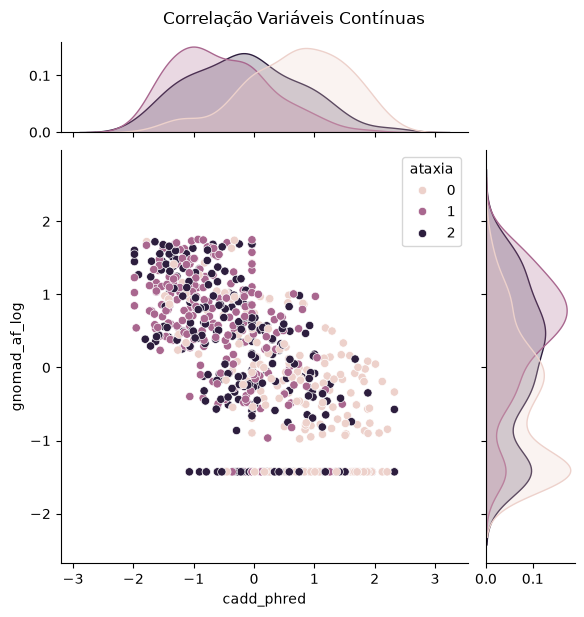

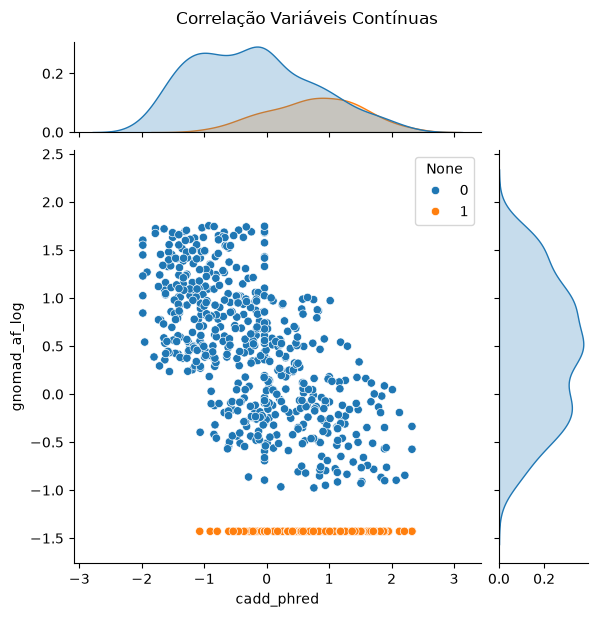

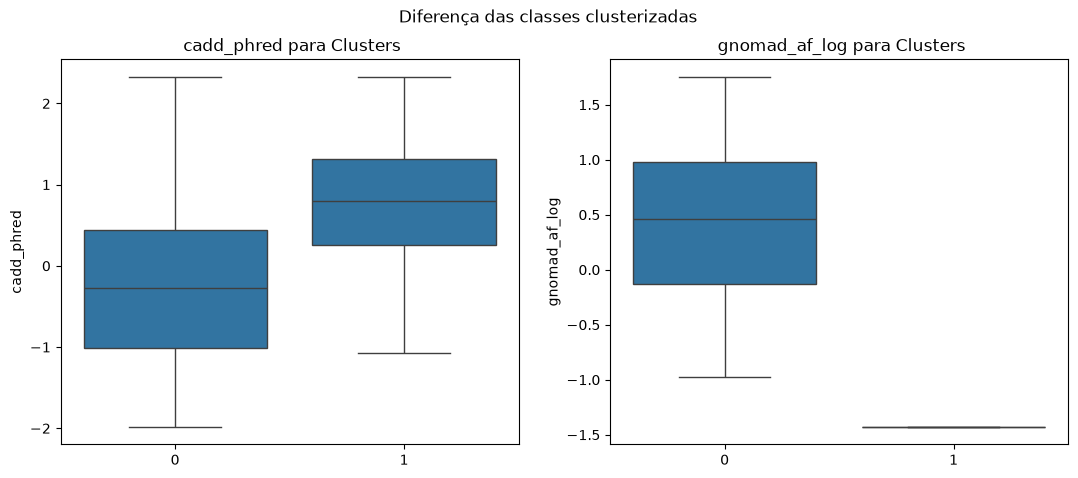


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 5, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.3200

Silhouette Score -> 0.434
Calinski Harabasz Score -> 5.781
Davies Bouldin Score -> 0.375
Adjusted Rand Score -> -0.0
Adjusted Mutual Info Score -> -0.0


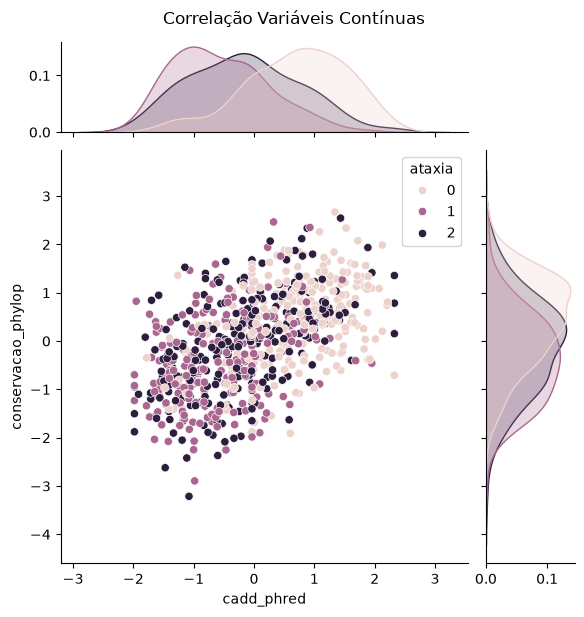

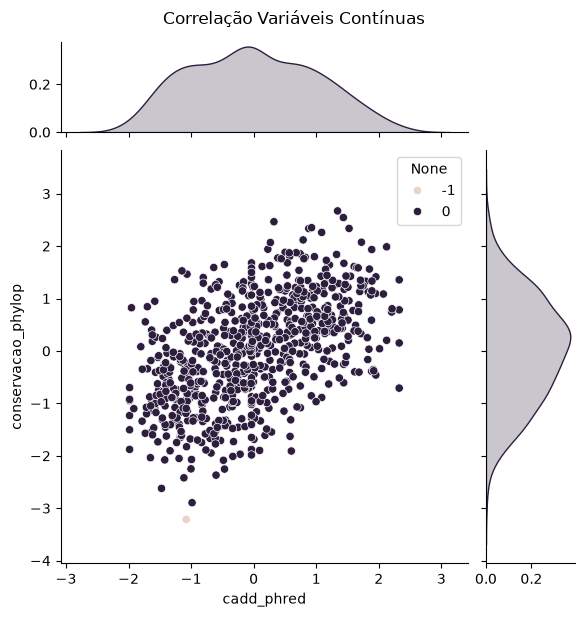

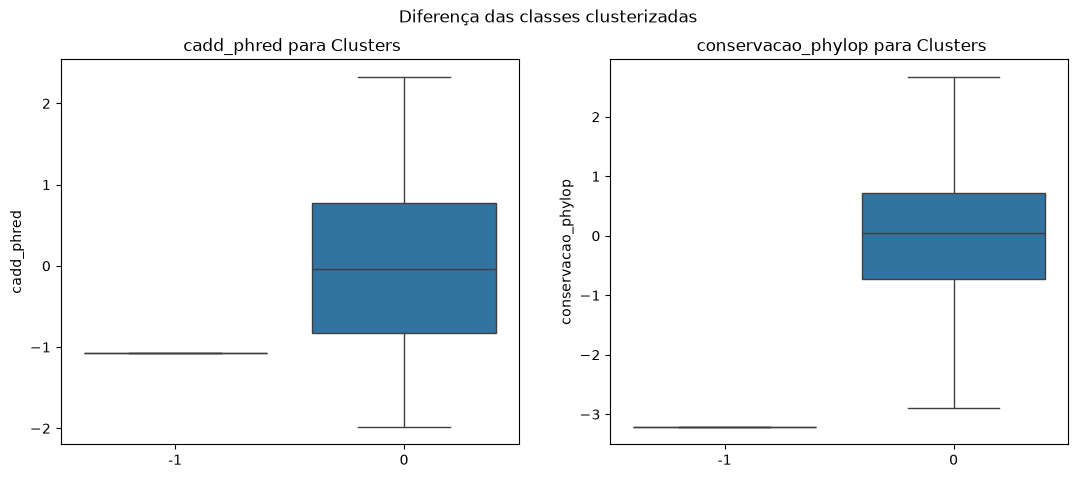


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 5, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2780

Silhouette Score -> 0.439
Calinski Harabasz Score -> 0.254
Davies Bouldin Score -> 8.442
Adjusted Rand Score -> -0.0
Adjusted Mutual Info Score -> 0.002


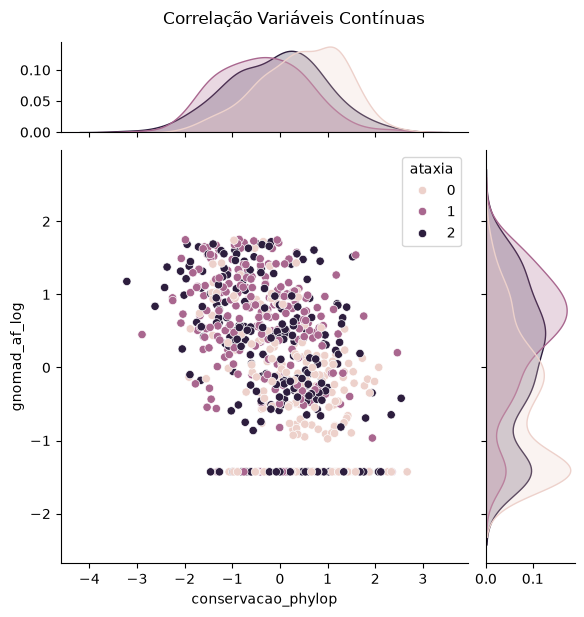

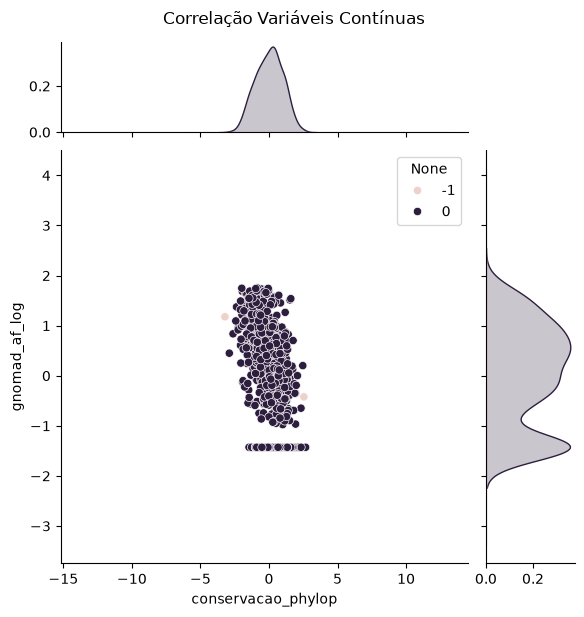

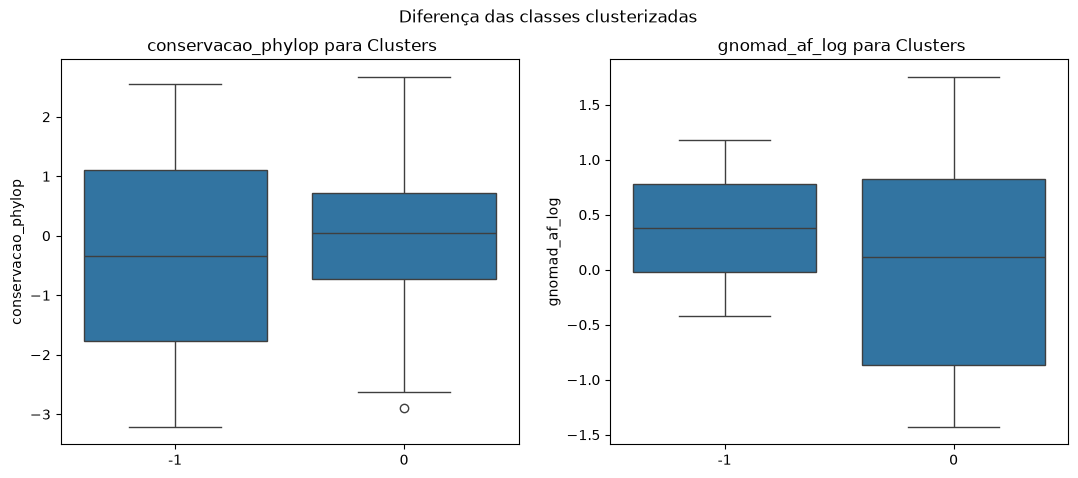


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2997

Silhouette Score -> 0.212
Calinski Harabasz Score -> 1.965
Davies Bouldin Score -> 0.635
Adjusted Rand Score -> -0.0
Adjusted Mutual Info Score -> -0.0


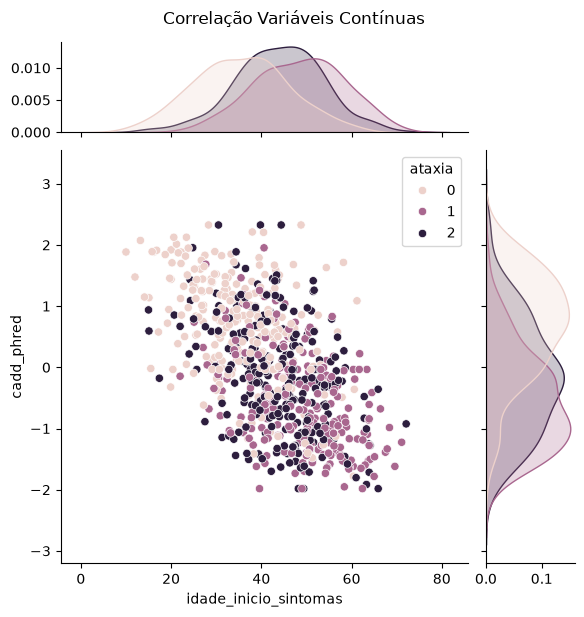

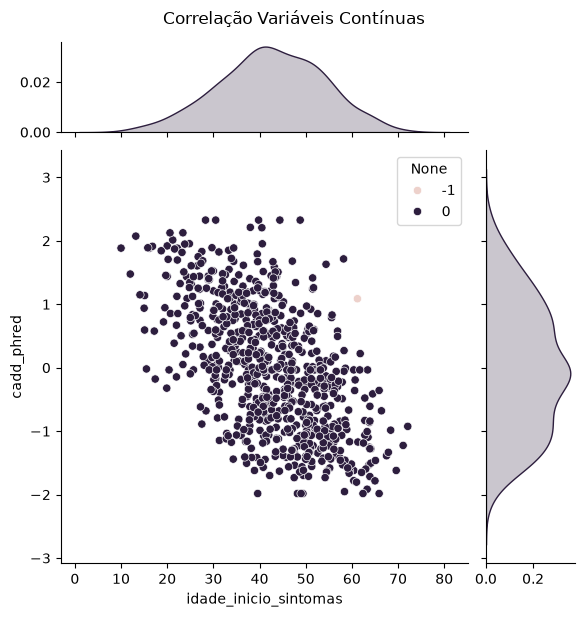

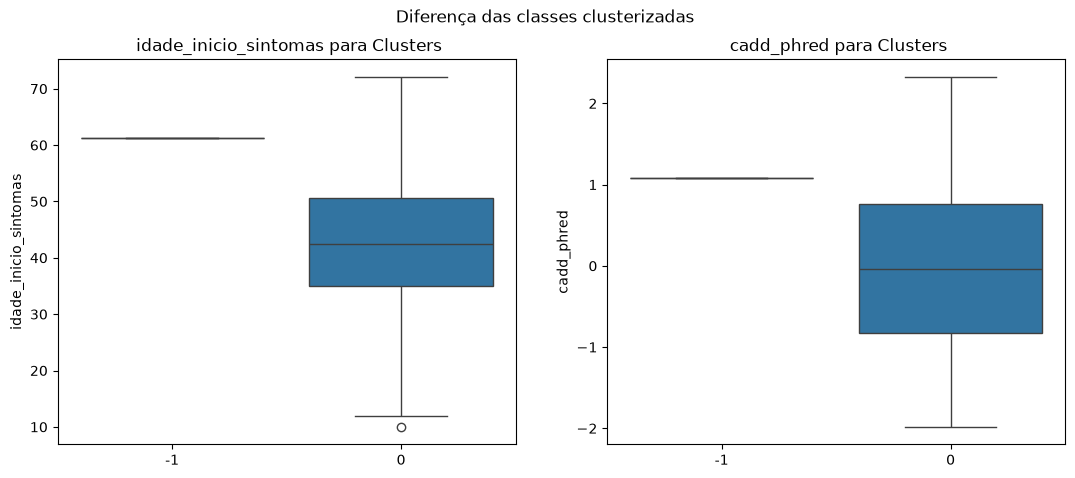


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 5, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2546

Silhouette Score -> 0.404
Calinski Harabasz Score -> 12.75
Davies Bouldin Score -> 2.035
Adjusted Rand Score -> 0.0
Adjusted Mutual Info Score -> -0.002


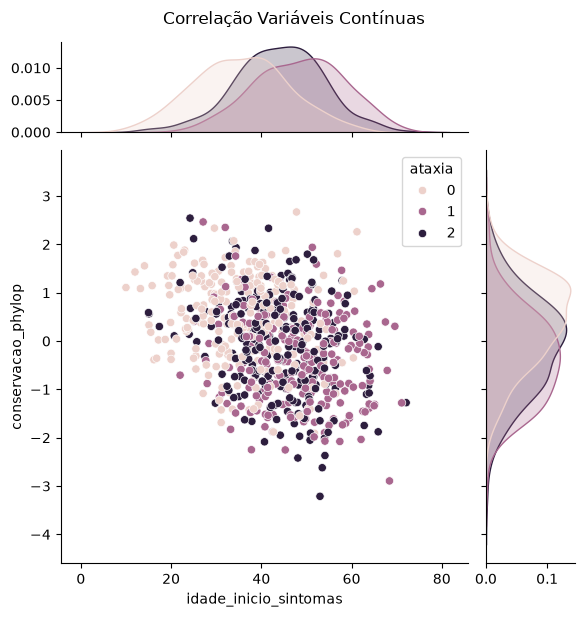

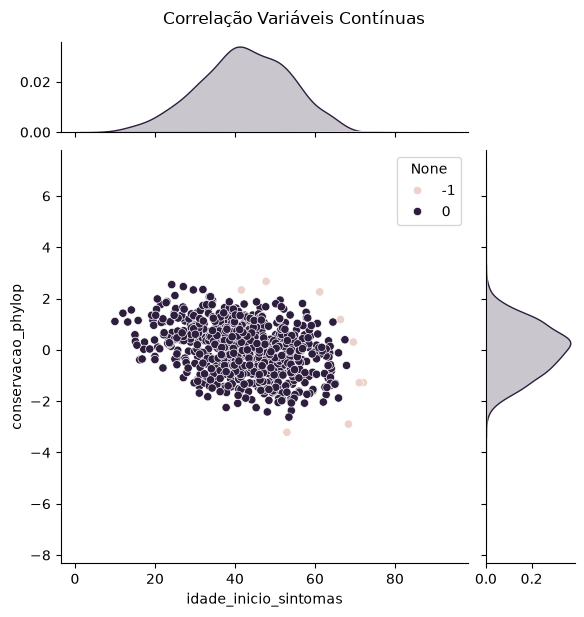

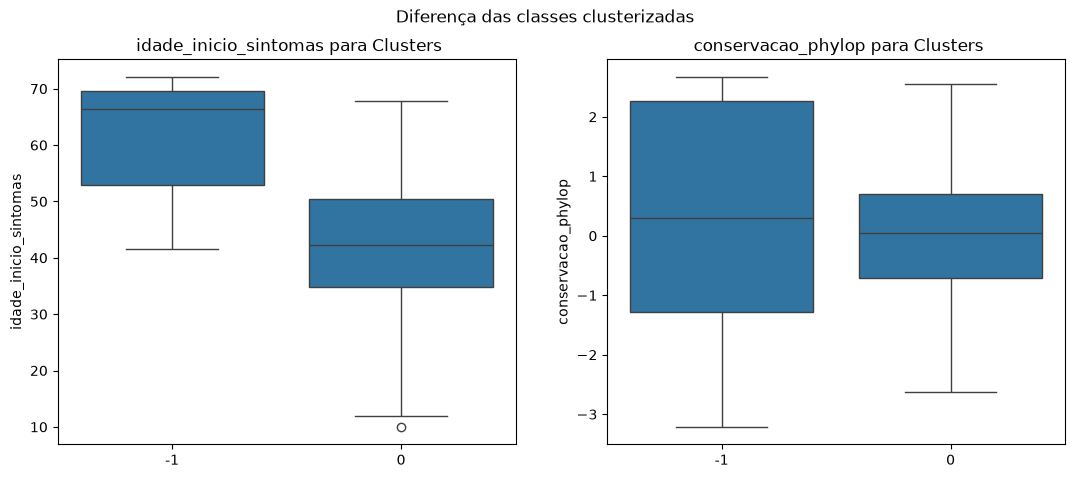


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 5, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.3016

Silhouette Score -> 0.371
Calinski Harabasz Score -> 4.722
Davies Bouldin Score -> 0.42
Adjusted Rand Score -> -0.0
Adjusted Mutual Info Score -> -0.0


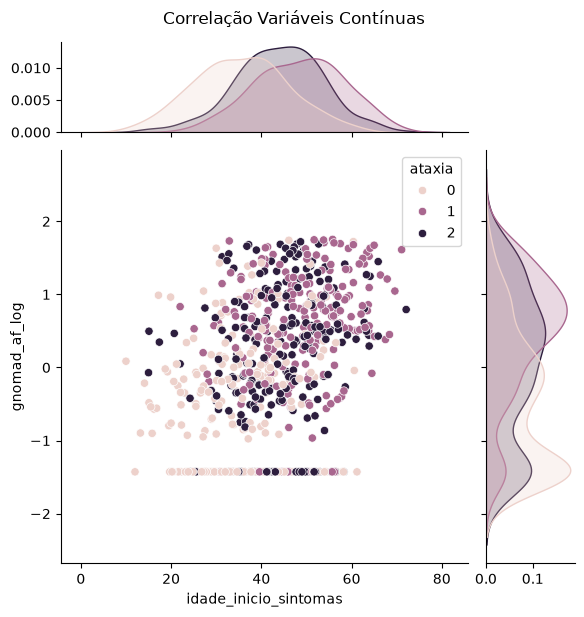

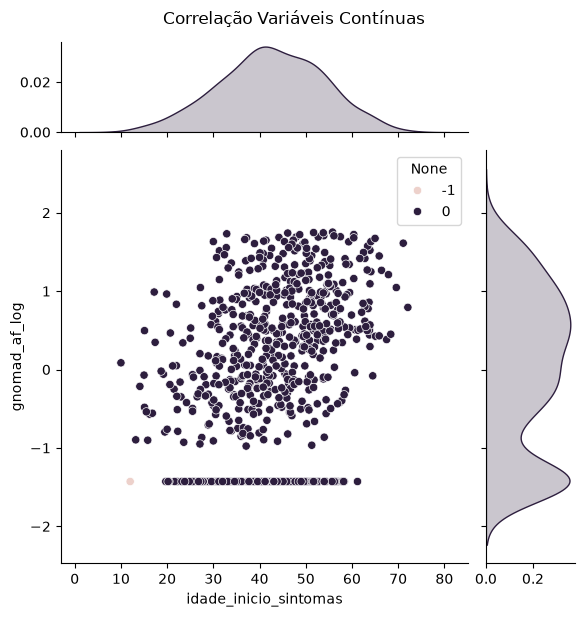

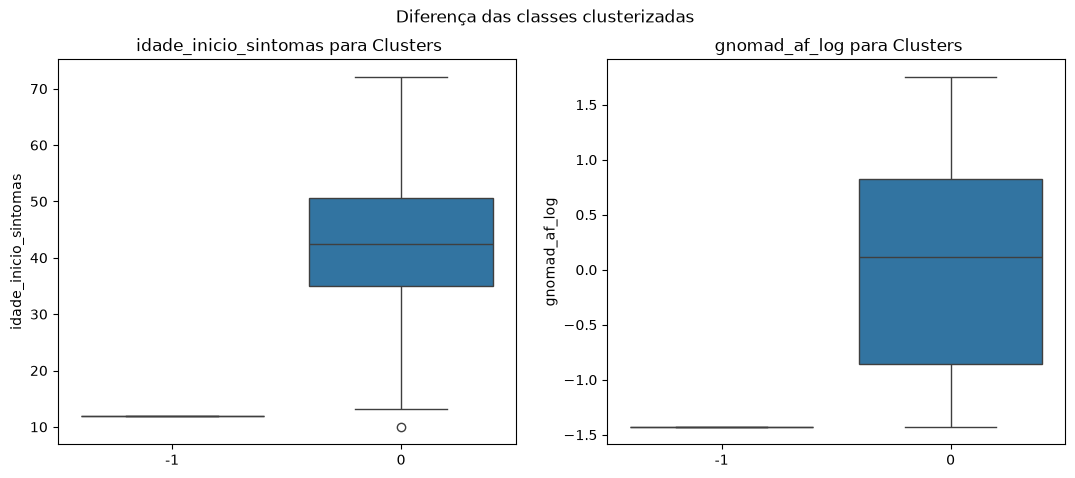

In [19]:
# Executando a validação cruzada para todas as combinações bivariadas cadastradas
print("=== CONJUNTO DE TREINO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_train, modelo=nome_modelo)
    cluster.cross_validation()

In [20]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.395,487.995,0.778,0.03,0.048
1,0.395,487.995,0.778,0.03,0.048
2,0.395,487.995,0.778,0.03,0.048
3,0.395,487.995,0.778,0.03,0.048
4,0.395,487.995,0.778,0.03,0.048


In [21]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,50.000,5.000000e+01,50.000,50.00,50.000
mean,0.395,4.879950e+02,0.778,0.03,0.048
std,0.000,5.742052e-14,0.000,0.00,0.000
min,0.395,4.879950e+02,0.778,0.03,0.048
25%,0.395,4.879950e+02,0.778,0.03,0.048
50%,0.395,4.879950e+02,0.778,0.03,0.048
75%,0.395,4.879950e+02,0.778,0.03,0.048
max,0.395,4.879950e+02,0.778,0.03,0.048


### Validação

In [22]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_dbscan = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_dbscan.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.142,3.187,4.46,-0.001,-0.003
1,0.142,3.187,4.46,-0.001,-0.003
2,0.142,3.187,4.46,-0.001,-0.003
3,0.142,3.187,4.46,-0.001,-0.003
4,0.142,3.187,4.46,-0.001,-0.003


In [23]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti_valid_dbscan.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,5.000000e+01,5.000000e+01,5.000000e+01,50.000,50.000
mean,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003
std,2.803737e-17,4.485978e-16,8.971957e-16,0.000,0.000
min,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003
25%,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003
50%,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003
75%,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003
max,1.420000e-01,3.187000e+00,4.460000e+00,-0.001,-0.003



=== CONJUNTO DE VALIDAÇÃO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.4295

Silhouette Score -> 0.142
Calinski Harabasz Score -> 3.187
Davies Bouldin Score -> 4.46
Adjusted Rand Score -> -0.001
Adjusted Mutual Info Score -> -0.003


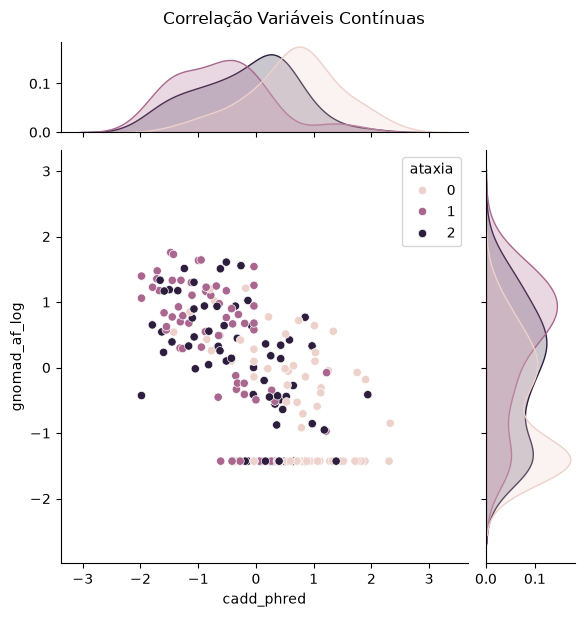

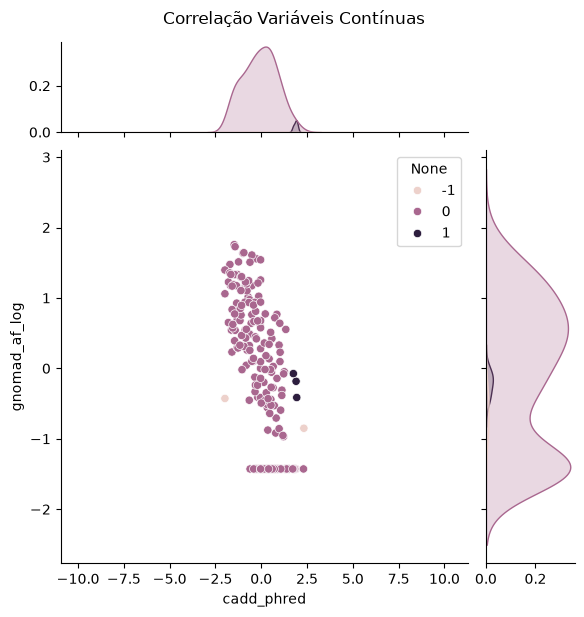

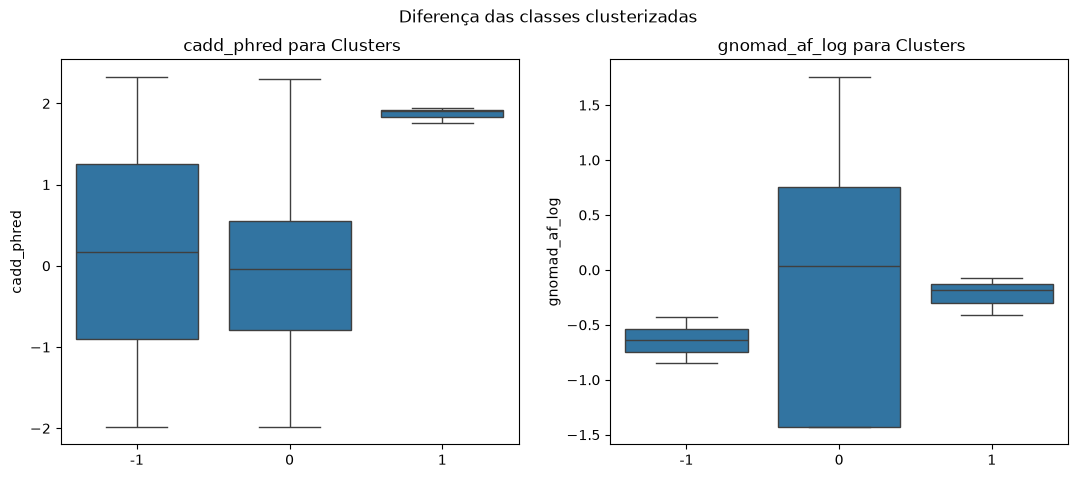


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2738

Silhouette Score -> 0.26
Calinski Harabasz Score -> 12.385
Davies Bouldin Score -> 2.549
Adjusted Rand Score -> 0.003
Adjusted Mutual Info Score -> 0.02


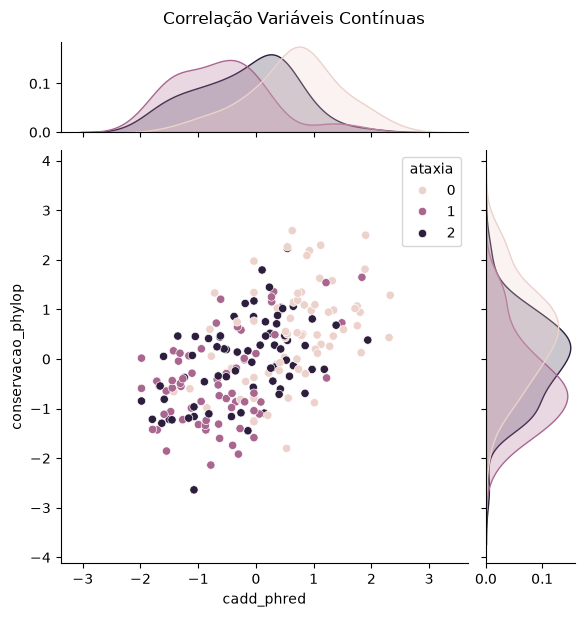

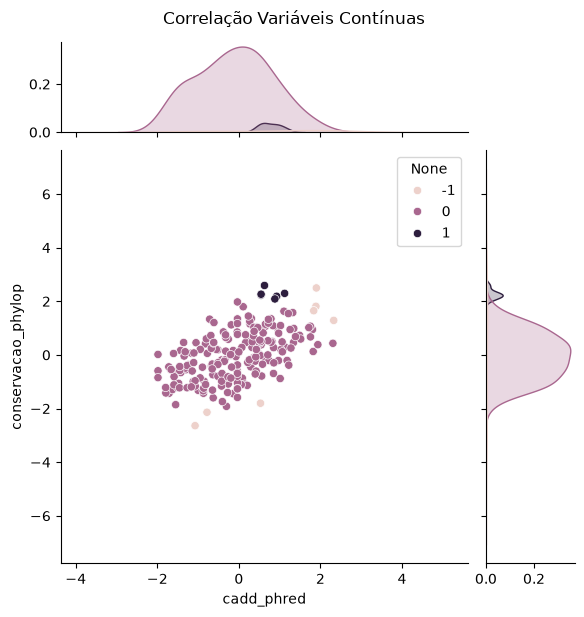

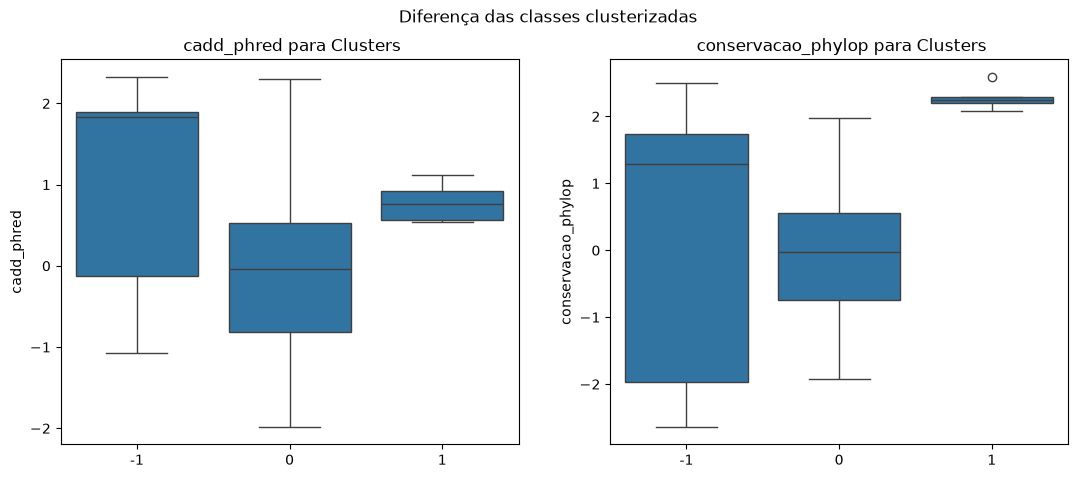


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.3019

Silhouette Score -> 0.313
Calinski Harabasz Score -> 0.581
Davies Bouldin Score -> 7.091
Adjusted Rand Score -> 0.001
Adjusted Mutual Info Score -> 0.015


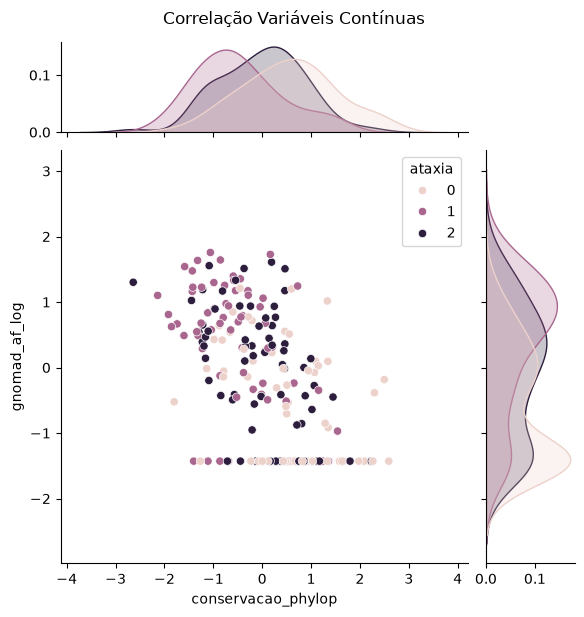

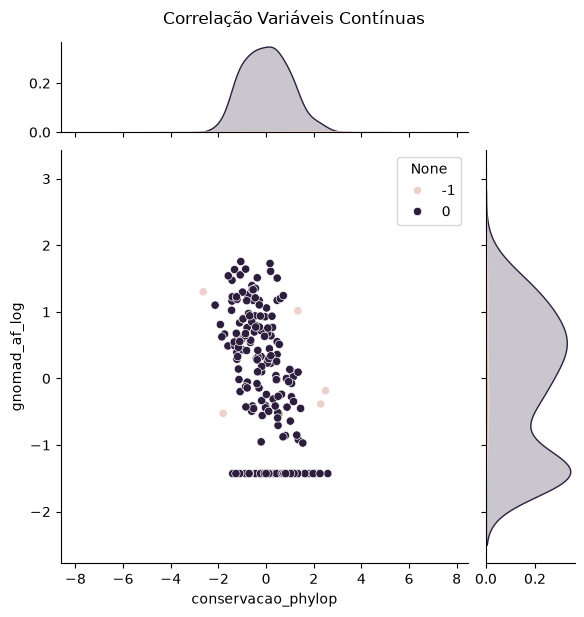

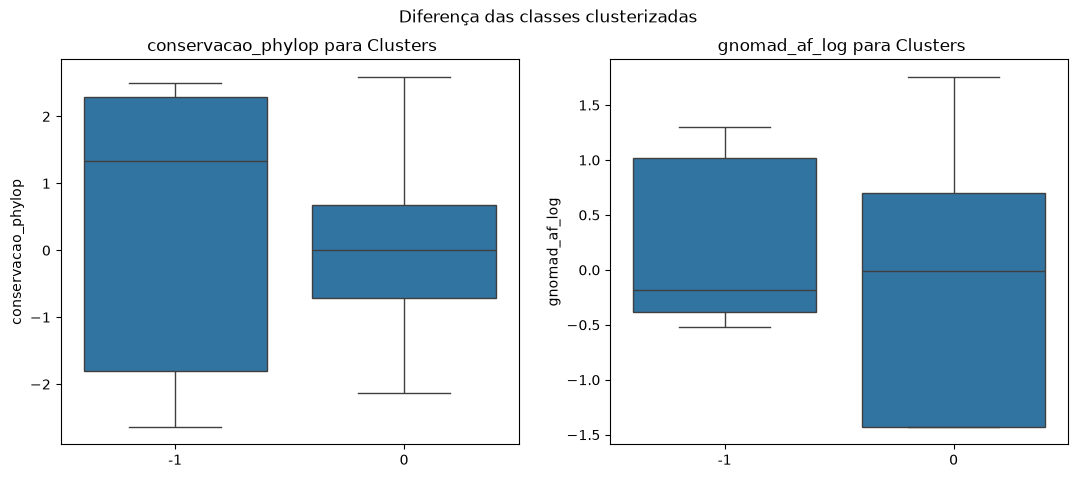


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2706

Silhouette Score -> 0.169
Calinski Harabasz Score -> 10.523
Davies Bouldin Score -> 5.852
Adjusted Rand Score -> 0.002
Adjusted Mutual Info Score -> 0.026


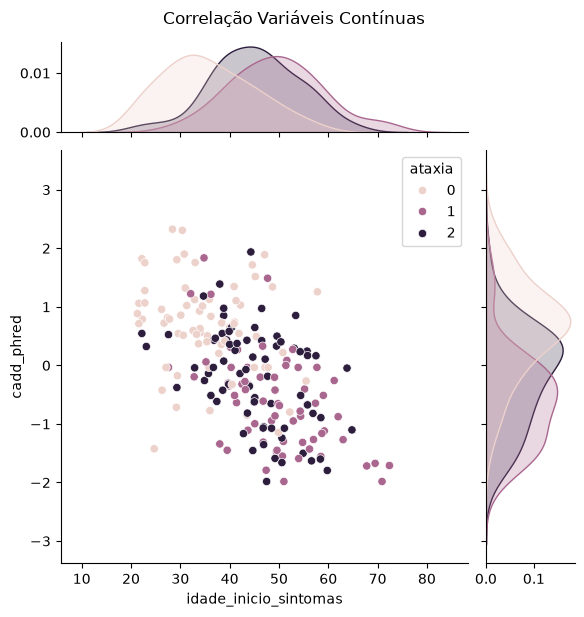

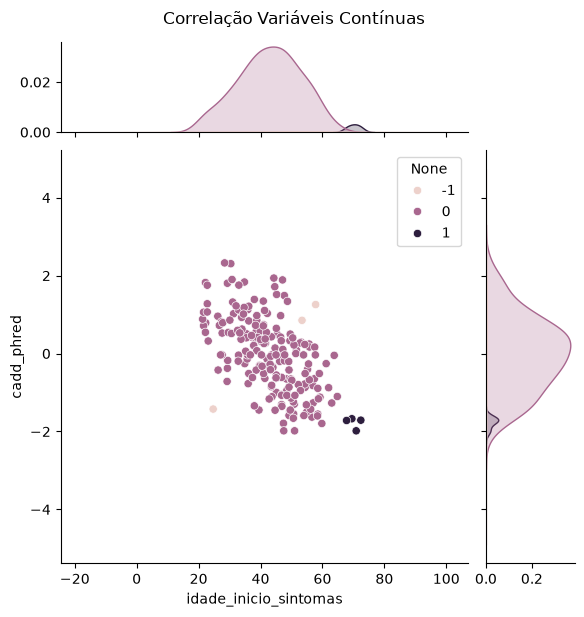

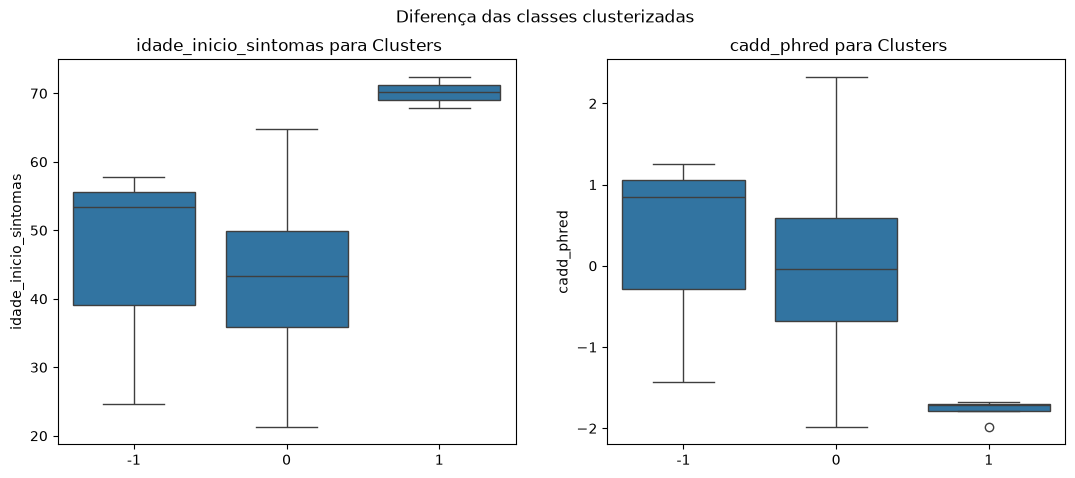


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2214

Silhouette Score -> 0.09
Calinski Harabasz Score -> 8.105
Davies Bouldin Score -> 4.579
Adjusted Rand Score -> 0.0
Adjusted Mutual Info Score -> 0.016


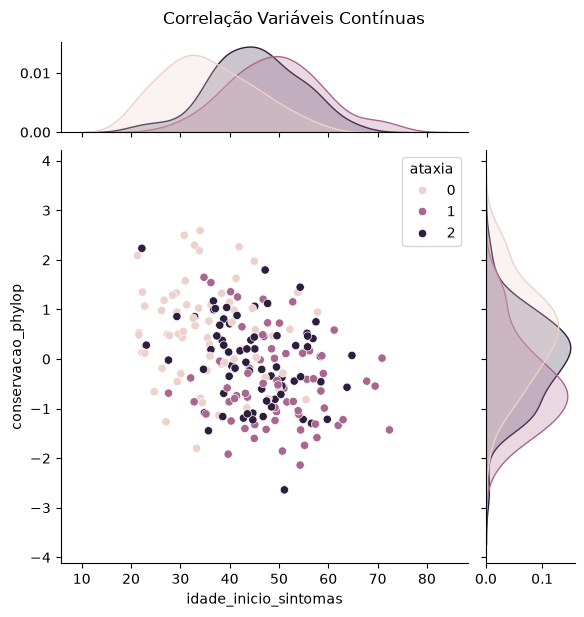

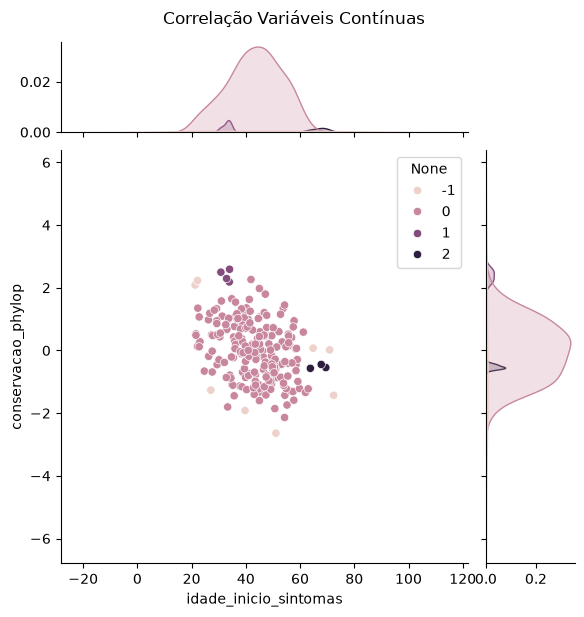

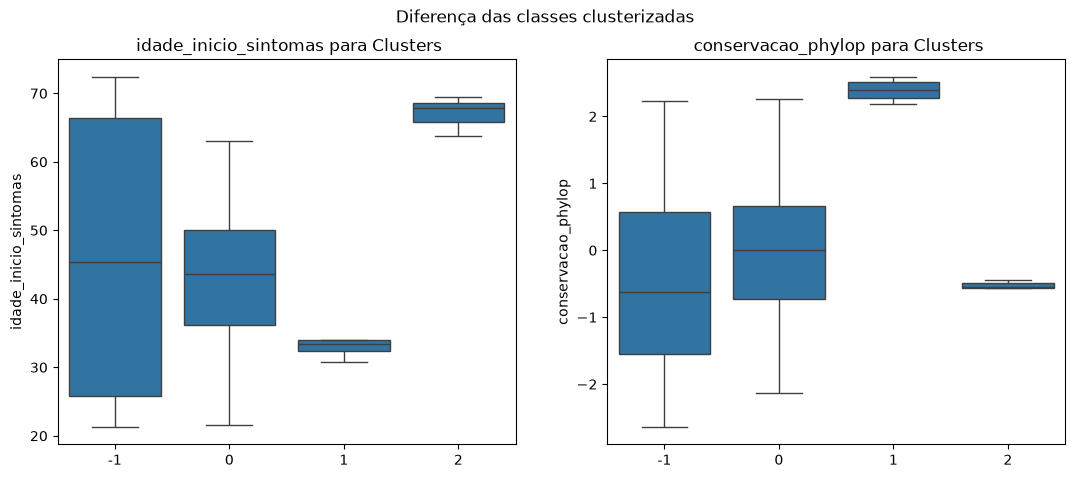


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.5, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.2988

Silhouette Score -> 0.173
Calinski Harabasz Score -> 9.97
Davies Bouldin Score -> 0.596
Adjusted Rand Score -> 0.002
Adjusted Mutual Info Score -> 0.027


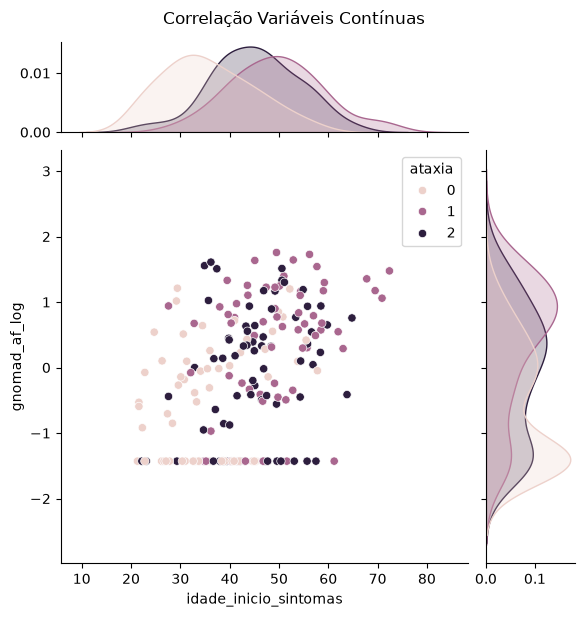

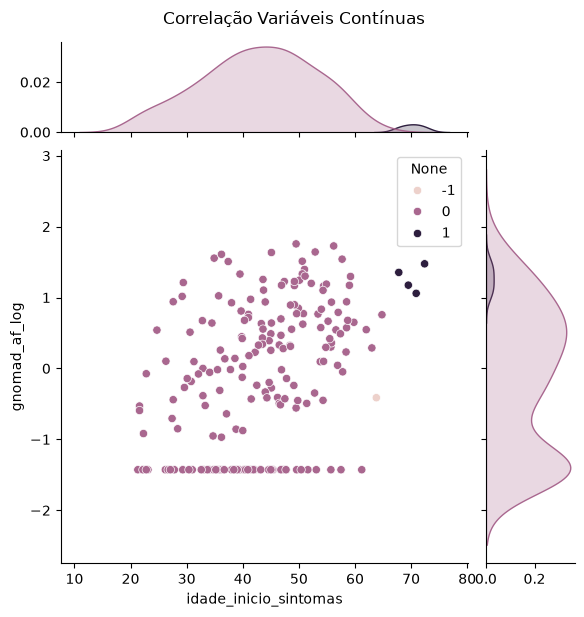

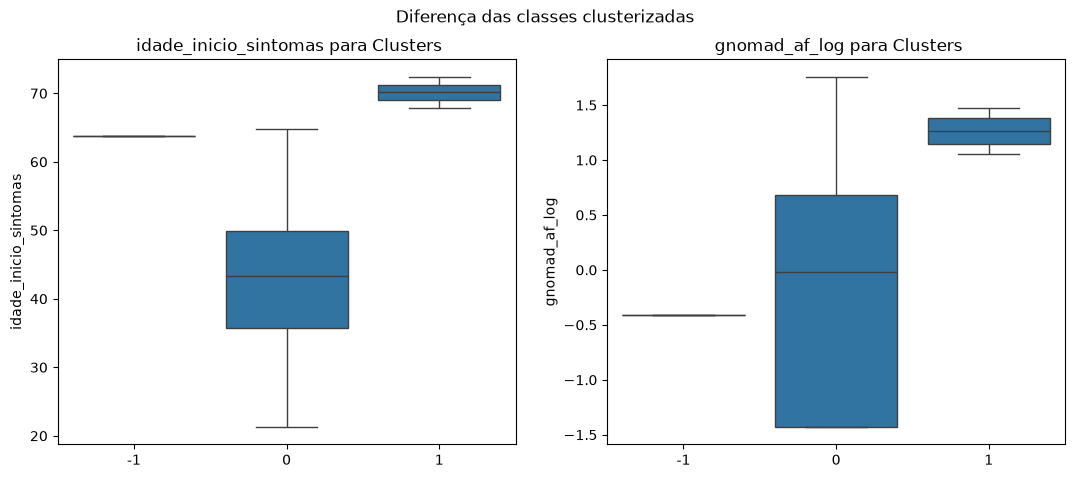

In [24]:
# Analisando os clusters 
print("\n=== CONJUNTO DE VALIDAÇÃO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_valid, modelo=nome_modelo)
    cluster.cross_validation()

## Agrupamento Hierarquico

### Treino

In [25]:
# Definindo um objeto de clustering com os dados de treino
nome_modelo = "agglomerative"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 0, 1, 1, 0])

In [26]:
# Obtendo as métricas de avaliação de clustering para todas as combinações de variáveis
data = {}
for i in colunas_num:
    for j in colunas_num:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
cadd_phred_conservacao_phylop,0.412,683.520,0.852,0.125,0.125
cadd_phred_profundidade_leitura,0.469,12.131,0.418,0.000,-0.001
cadd_phred_gnomad_af_log,0.499,1076.197,0.735,0.128,0.123
cadd_phred_idade_inicio_sintomas,0.400,625.671,0.865,0.136,0.152
conservacao_phylop_cadd_phred,0.412,683.520,0.852,0.125,0.125
conservacao_phylop_profundidade_leitura,0.358,66.505,0.834,0.000,0.000
conservacao_phylop_gnomad_af_log,0.436,772.515,0.867,0.108,0.097
conservacao_phylop_idade_inicio_sintomas,0.361,24.640,0.653,-0.000,0.004
profundidade_leitura_cadd_phred,0.469,12.131,0.418,0.000,-0.001
profundidade_leitura_conservacao_phylop,0.358,66.505,0.834,0.000,0.000


In [27]:
'''Selecionando as melhores combinações de variáveis com base nas métricas de avaliação de clustering 
(maior Silhouette, Calinski-Harabasz, Adjusted Rand e Adjusted Mutual Info; menor Davies-Bouldin)'''

display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nlargest(1))
display(df_metricas["Davies Bouldin"].nsmallest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

cadd_phred_gnomad_af_log    0.499
Name: Silhouette, dtype: float64

cadd_phred_gnomad_af_log    1076.197
Name: Calinski Harabasz, dtype: float64

profundidade_leitura_idade_inicio_sintomas    0.351
Name: Davies Bouldin, dtype: float64

cadd_phred_idade_inicio_sintomas    0.136
Name: Adjusted Rand, dtype: float64

cadd_phred_idade_inicio_sintomas    0.152
Name: Adjusted Mutual Info, dtype: float64

=== CONJUNTO DE TREINO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'average'}
Silhouette Score Médio (CV): 0.4819

Silhouette Score -> 0.499
Calinski Harabasz Score -> 1076.197
Davies Bouldin Score -> 0.735
Adjusted Rand Score -> 0.128
Adjusted Mutual Info Score -> 0.123


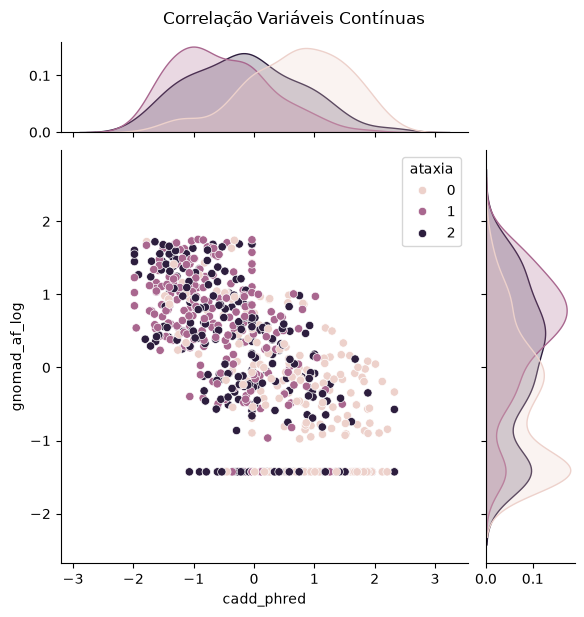

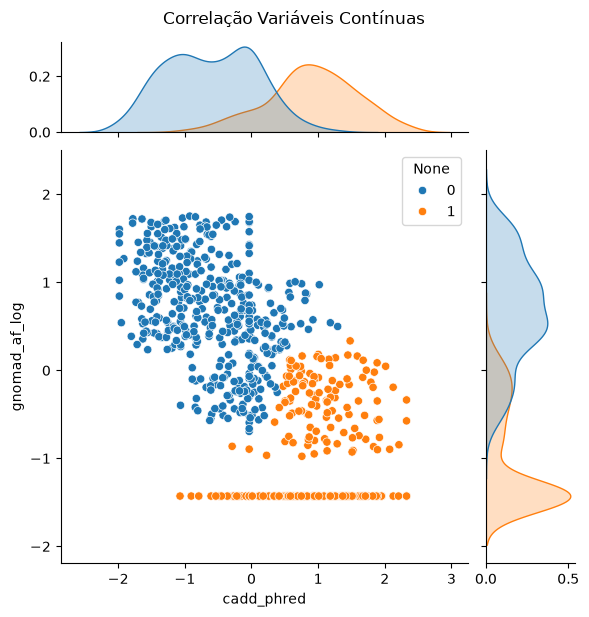

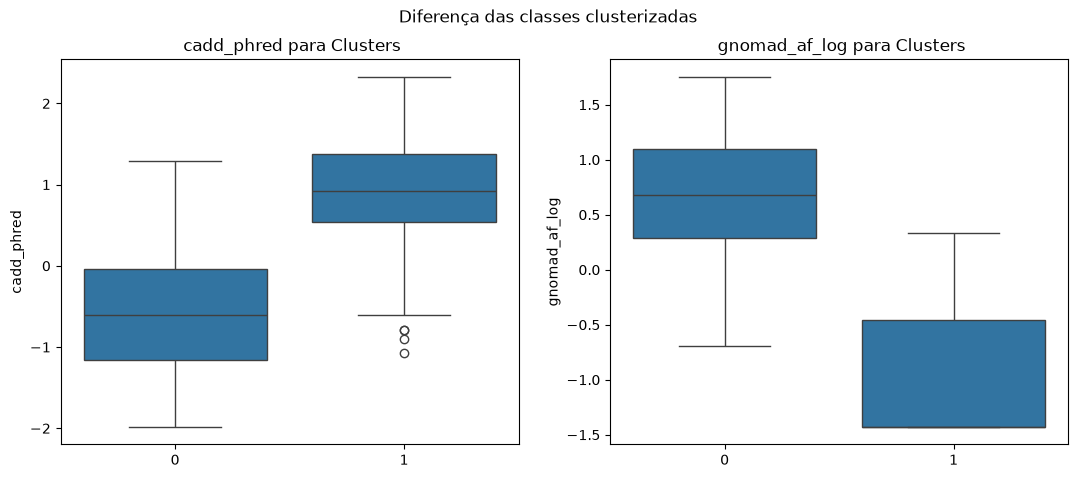


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4484

Silhouette Score -> 0.412
Calinski Harabasz Score -> 683.52
Davies Bouldin Score -> 0.852
Adjusted Rand Score -> 0.125
Adjusted Mutual Info Score -> 0.125


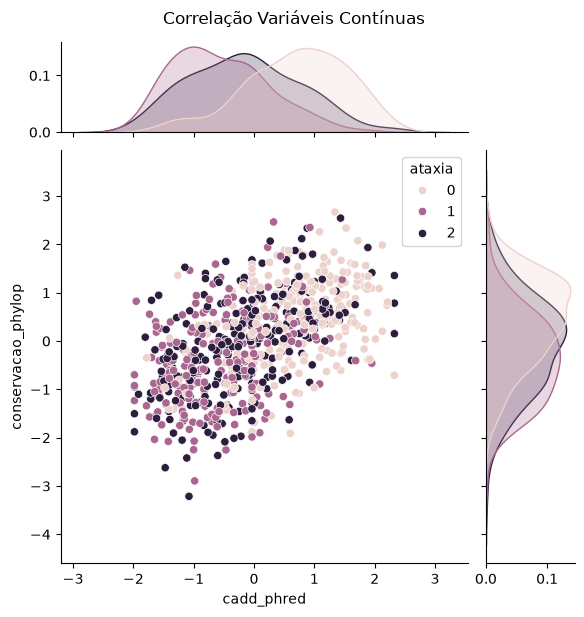

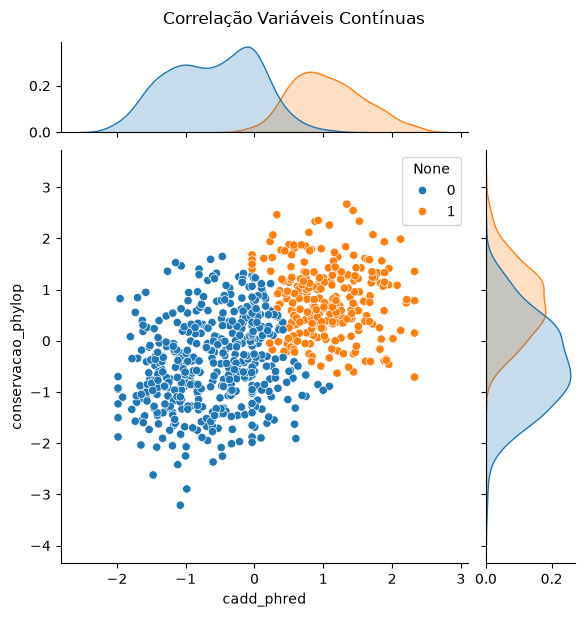

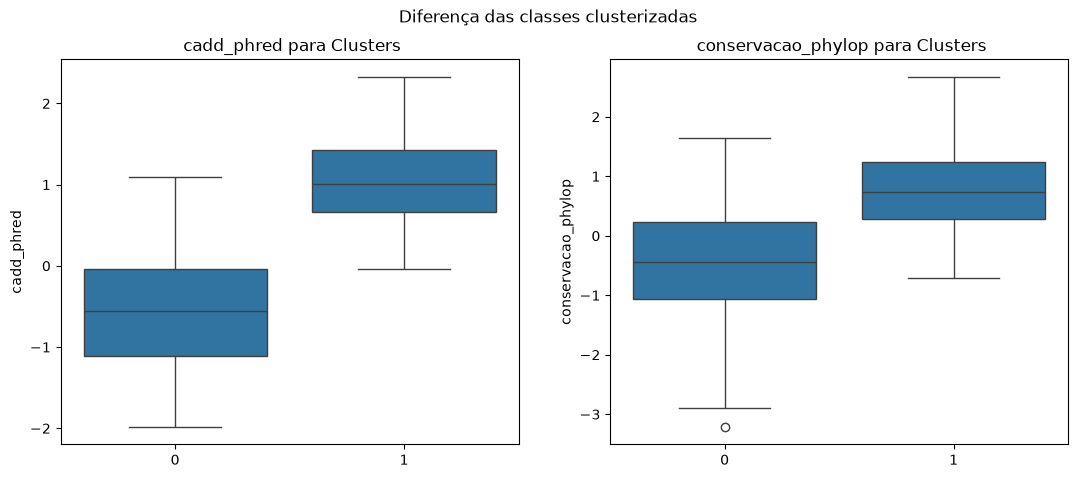


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4234

Silhouette Score -> 0.436
Calinski Harabasz Score -> 772.515
Davies Bouldin Score -> 0.867
Adjusted Rand Score -> 0.108
Adjusted Mutual Info Score -> 0.097


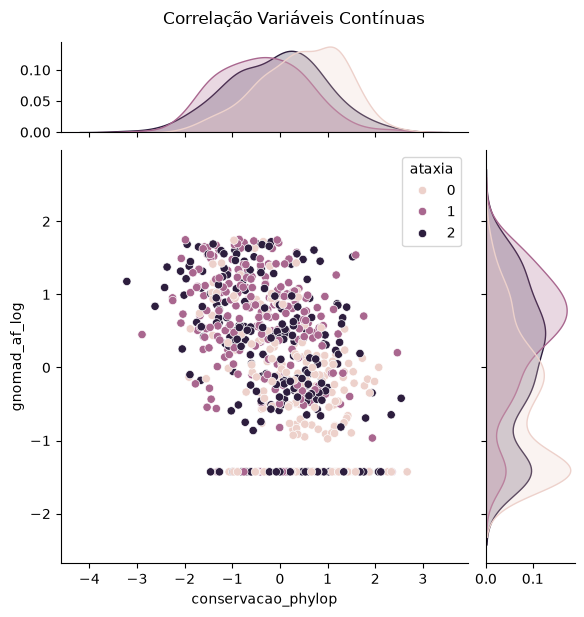

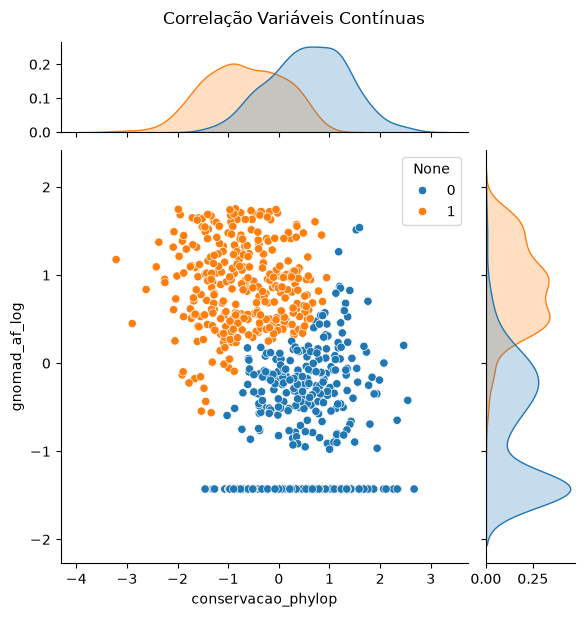

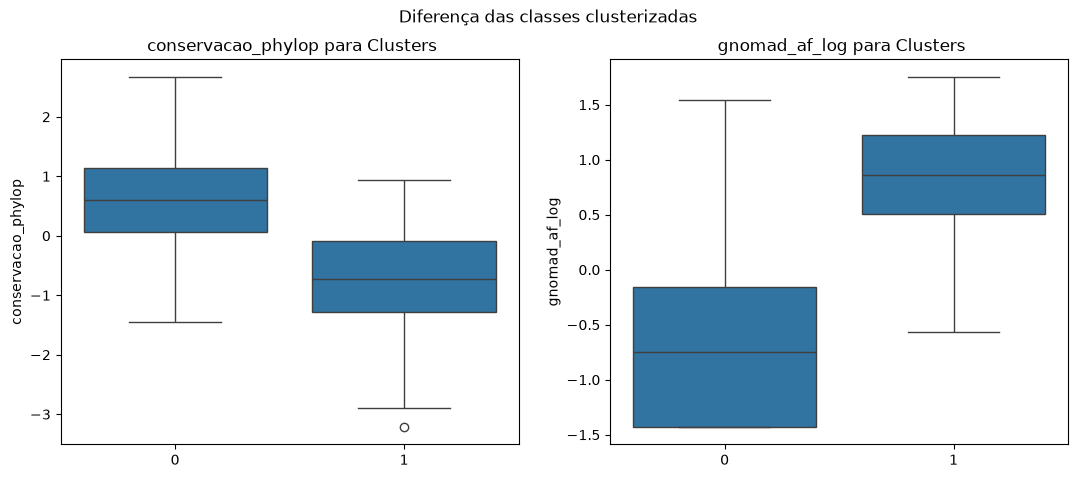


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'average'}
Silhouette Score Médio (CV): 0.4398

Silhouette Score -> 0.4
Calinski Harabasz Score -> 625.671
Davies Bouldin Score -> 0.865
Adjusted Rand Score -> 0.136
Adjusted Mutual Info Score -> 0.152


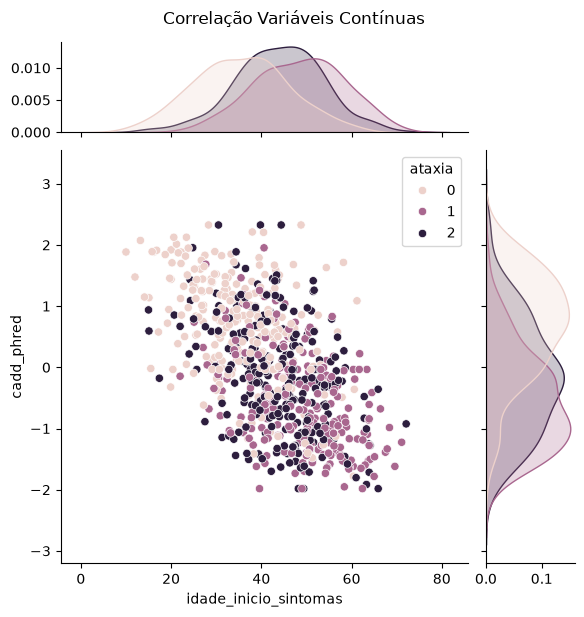

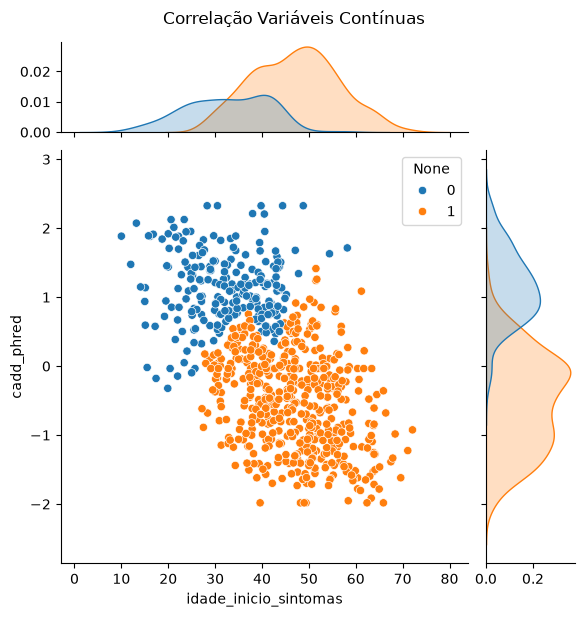

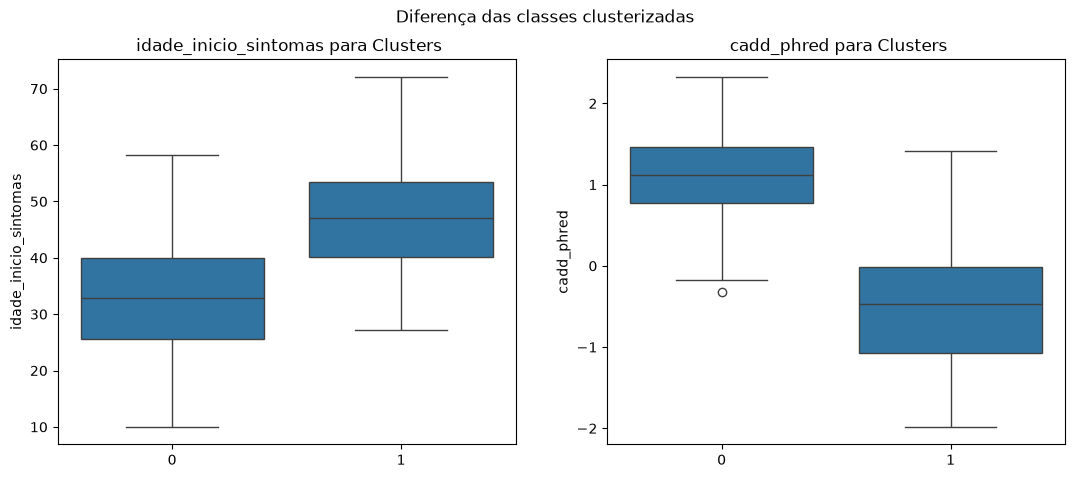


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'average'}
Silhouette Score Médio (CV): 0.3855

Silhouette Score -> 0.361
Calinski Harabasz Score -> 24.64
Davies Bouldin Score -> 0.653
Adjusted Rand Score -> -0.0
Adjusted Mutual Info Score -> 0.004


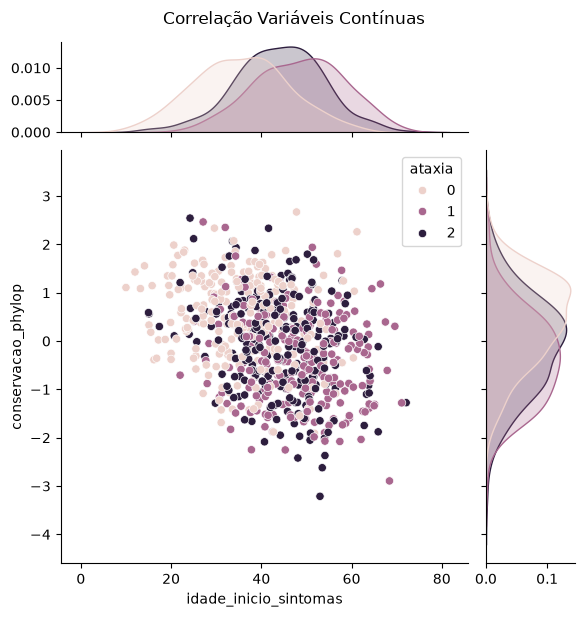

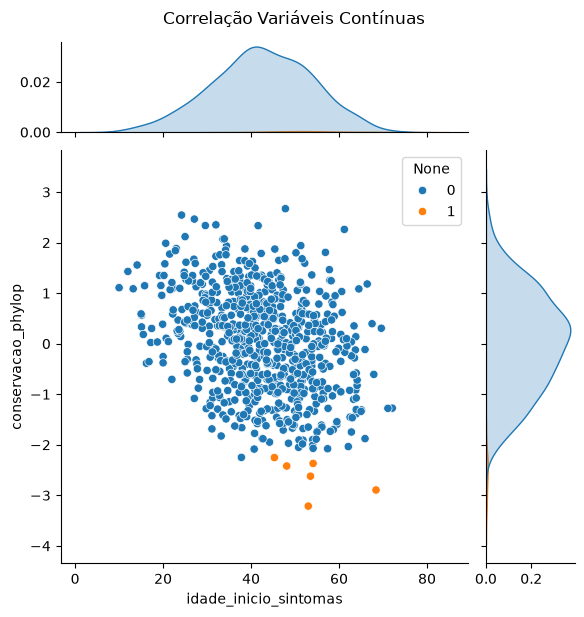

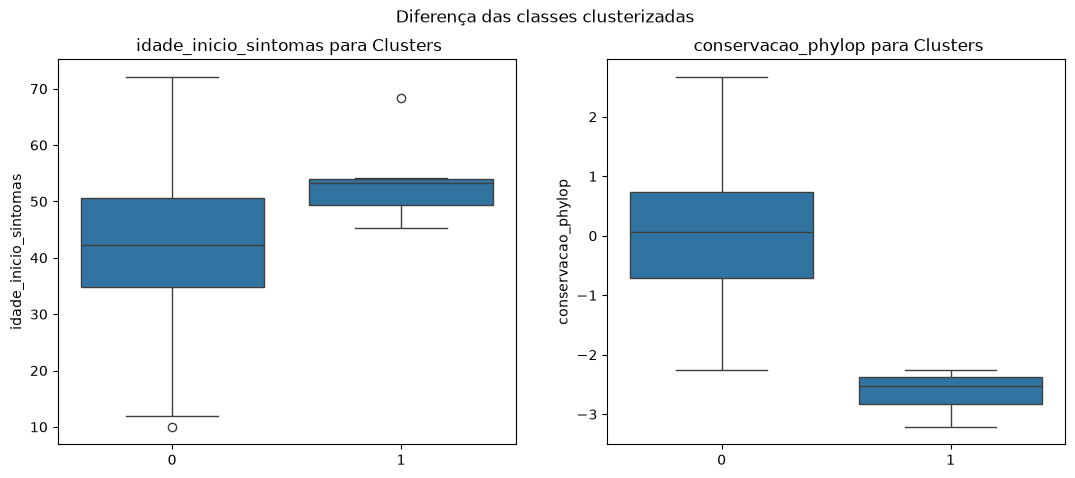


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4107

Silhouette Score -> 0.347
Calinski Harabasz Score -> 455.825
Davies Bouldin Score -> 0.895
Adjusted Rand Score -> 0.074
Adjusted Mutual Info Score -> 0.094


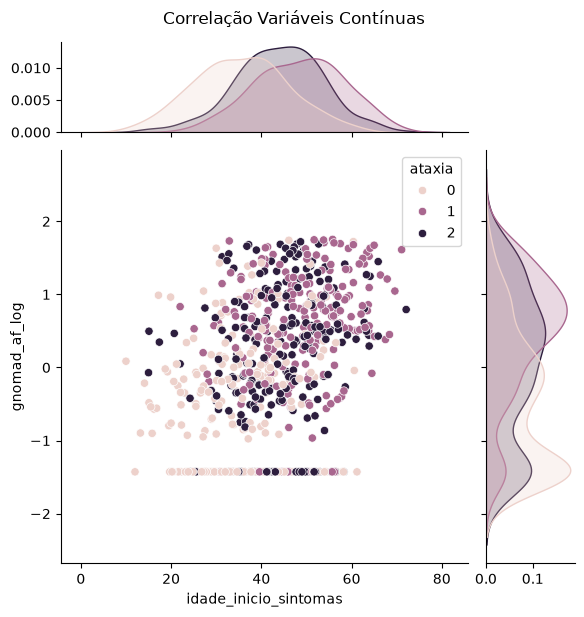

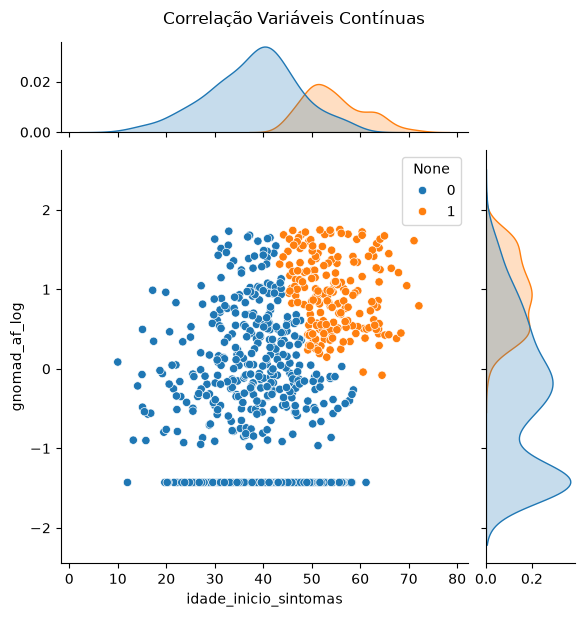

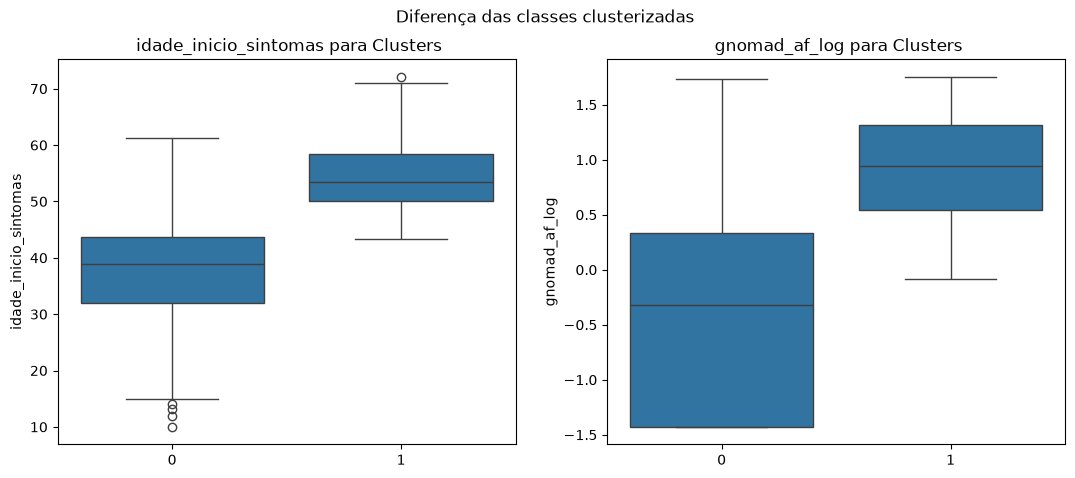

In [28]:
# Executando a validação cruzada para todas as combinações bivariadas cadastradas
print("=== CONJUNTO DE TREINO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_train, modelo=nome_modelo)
    cluster.cross_validation()

In [29]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.499,1076.197,0.735,0.128,0.123
1,0.499,1076.197,0.735,0.128,0.123
2,0.499,1076.197,0.735,0.128,0.123
3,0.499,1076.197,0.735,0.128,0.123
4,0.499,1076.197,0.735,0.128,0.123


In [30]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,50.000,50.000,50.000,50.000,5.000000e+01
mean,0.499,1076.197,0.735,0.128,1.230000e-01
std,0.000,0.000,0.000,0.000,1.401868e-17
min,0.499,1076.197,0.735,0.128,1.230000e-01
25%,0.499,1076.197,0.735,0.128,1.230000e-01
50%,0.499,1076.197,0.735,0.128,1.230000e-01
75%,0.499,1076.197,0.735,0.128,1.230000e-01
max,0.499,1076.197,0.735,0.128,1.230000e-01


### Validação

In [31]:
# Repetindo as análises de clustering para a primeira combinação de variáveis, 50 vezes, para verificar a estabilidade das métricas de avaliação
data = {}
for i in range(50):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_agg = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_agg.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.513,330.671,0.681,0.13,0.128
1,0.513,330.671,0.681,0.13,0.128
2,0.513,330.671,0.681,0.13,0.128
3,0.513,330.671,0.681,0.13,0.128
4,0.513,330.671,0.681,0.13,0.128


In [32]:
# Analisando as métricas de avaliação de clustering repetidas 50 vezes
df_metricas_repeti_valid_agg.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,50.000,50.000,5.000000e+01,50.00,50.000
mean,0.513,330.671,6.810000e-01,0.13,0.128
std,0.000,0.000,1.121495e-16,0.00,0.000
min,0.513,330.671,6.810000e-01,0.13,0.128
25%,0.513,330.671,6.810000e-01,0.13,0.128
50%,0.513,330.671,6.810000e-01,0.13,0.128
75%,0.513,330.671,6.810000e-01,0.13,0.128
max,0.513,330.671,6.810000e-01,0.13,0.128



=== CONJUNTO DE VALIDAÇÃO ===

Analisando bivariada 0: cadd_phred vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.5299

Silhouette Score -> 0.513
Calinski Harabasz Score -> 330.671
Davies Bouldin Score -> 0.681
Adjusted Rand Score -> 0.13
Adjusted Mutual Info Score -> 0.128


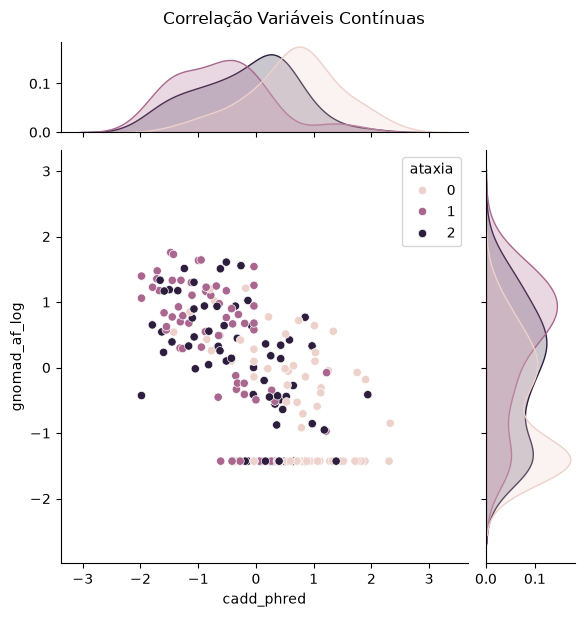

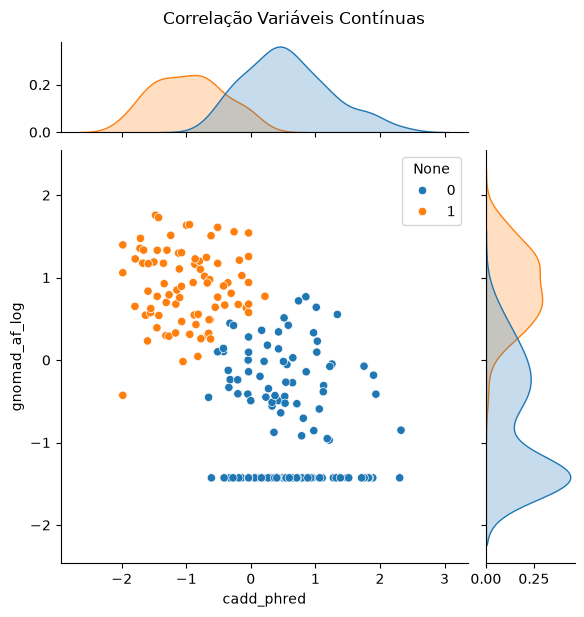

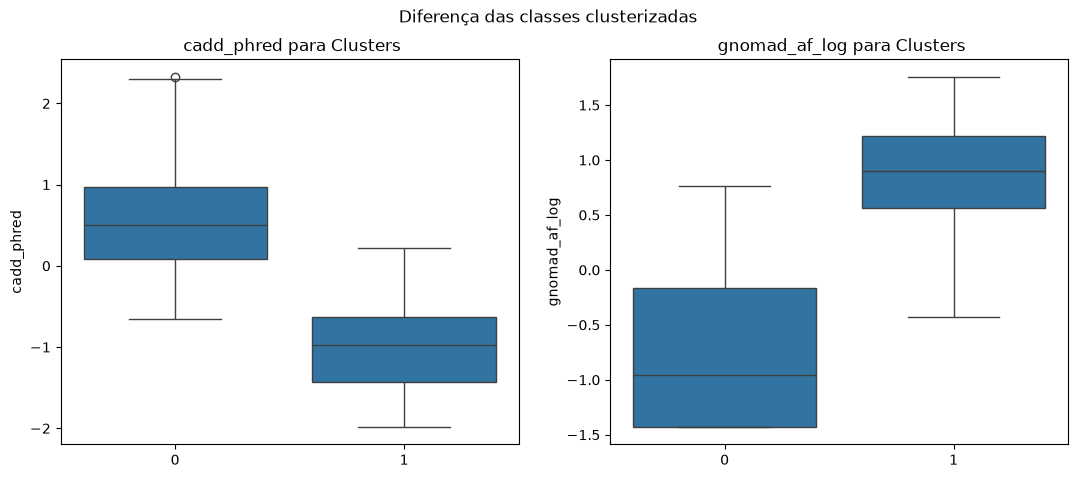


Analisando bivariada 1: cadd_phred vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4495

Silhouette Score -> 0.395
Calinski Harabasz Score -> 182.342
Davies Bouldin Score -> 0.884
Adjusted Rand Score -> 0.069
Adjusted Mutual Info Score -> 0.071


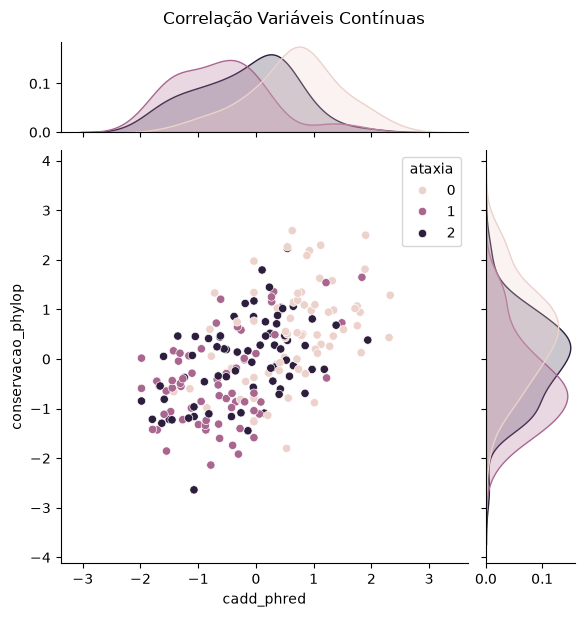

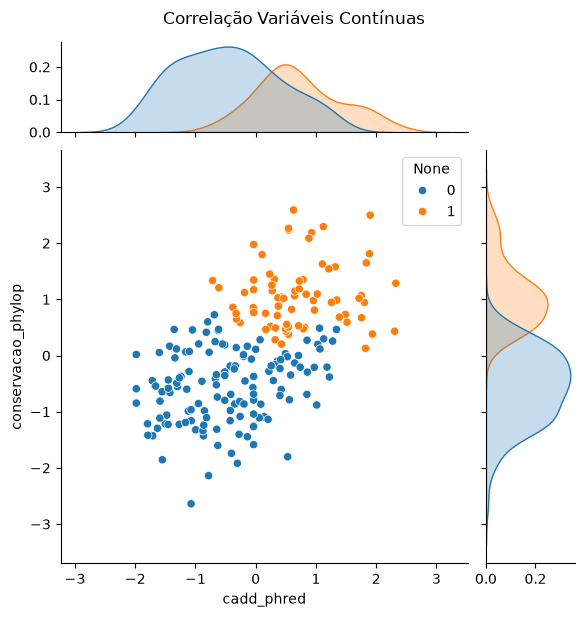

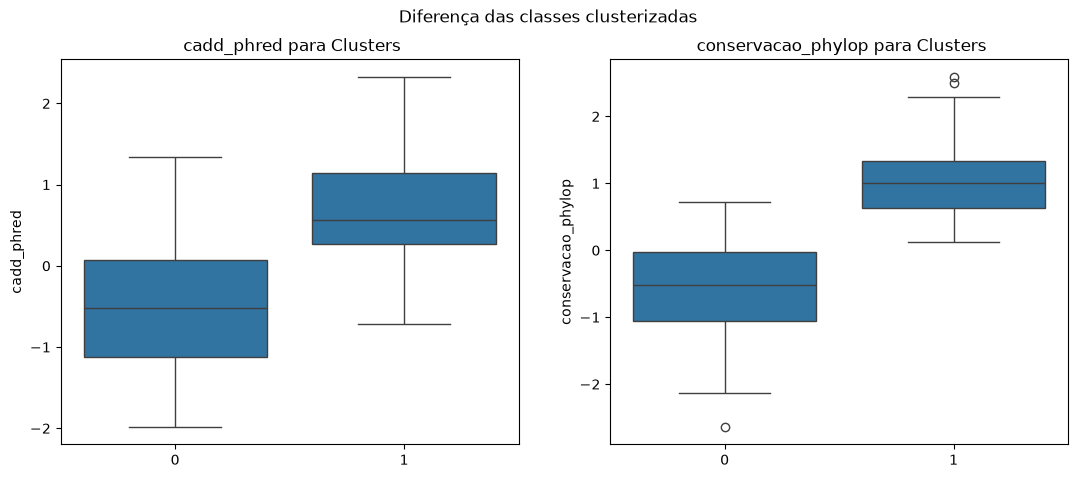


Analisando bivariada 2: conservacao_phylop vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4807

Silhouette Score -> 0.427
Calinski Harabasz Score -> 223.651
Davies Bouldin Score -> 0.83
Adjusted Rand Score -> 0.085
Adjusted Mutual Info Score -> 0.078


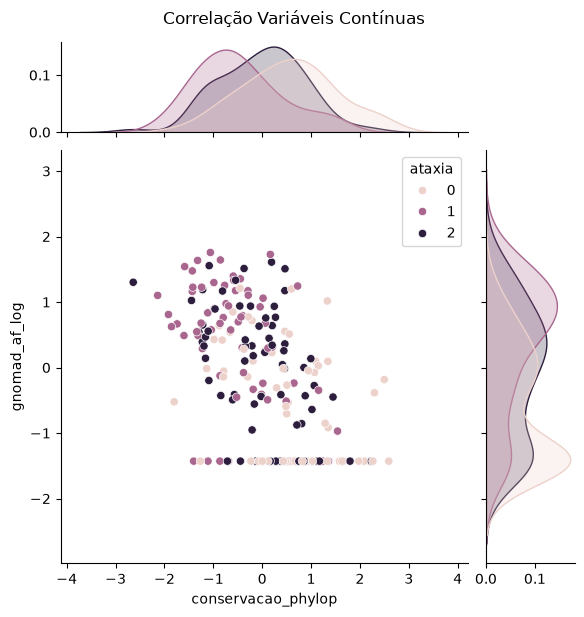

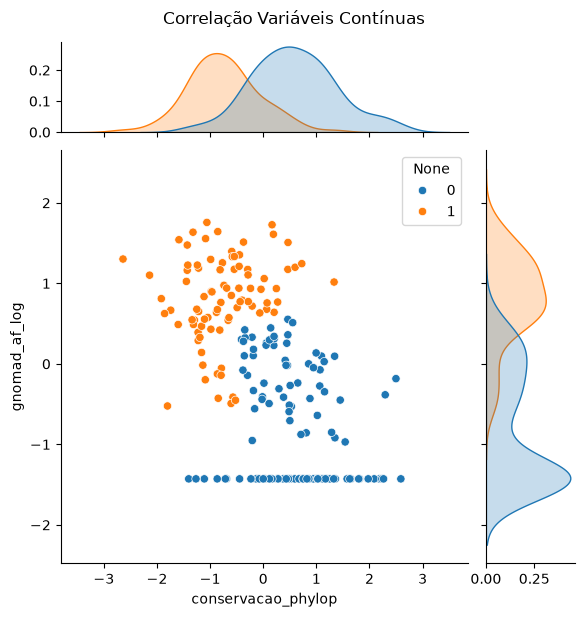

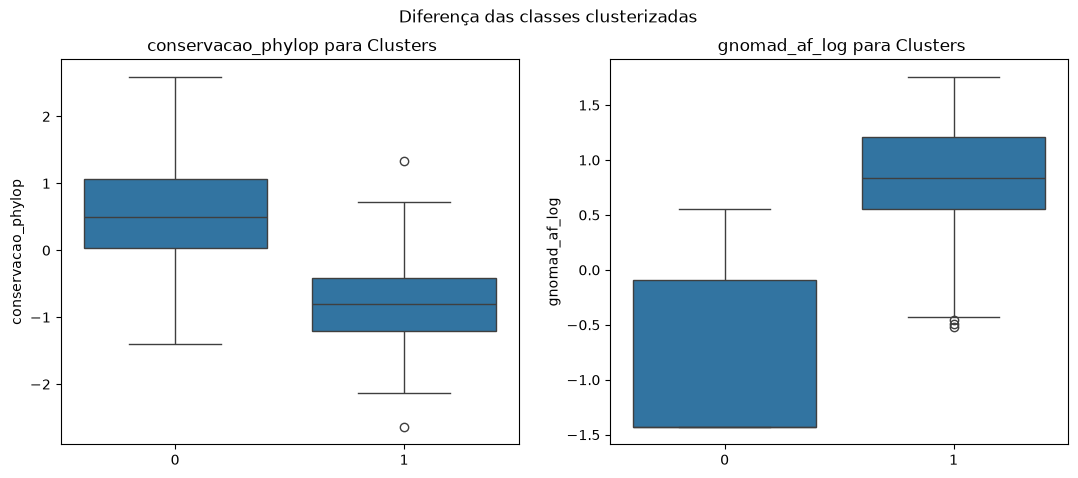


Analisando bivariada 3: idade_inicio_sintomas vs cadd_phred
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4580

Silhouette Score -> 0.43
Calinski Harabasz Score -> 226.767
Davies Bouldin Score -> 0.847
Adjusted Rand Score -> 0.177
Adjusted Mutual Info Score -> 0.164


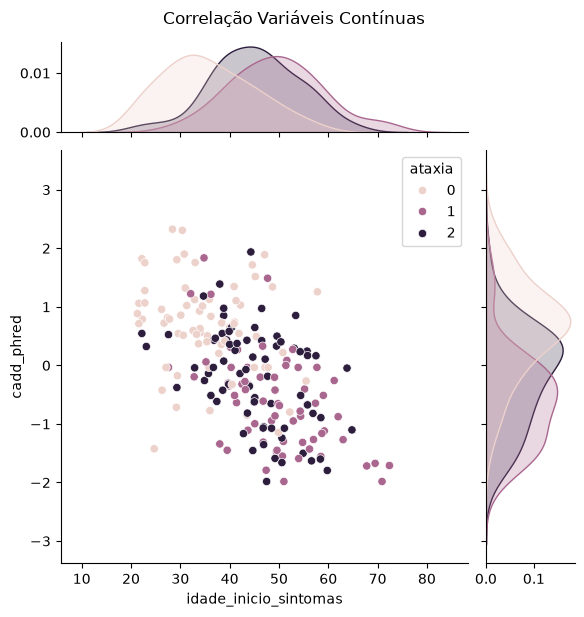

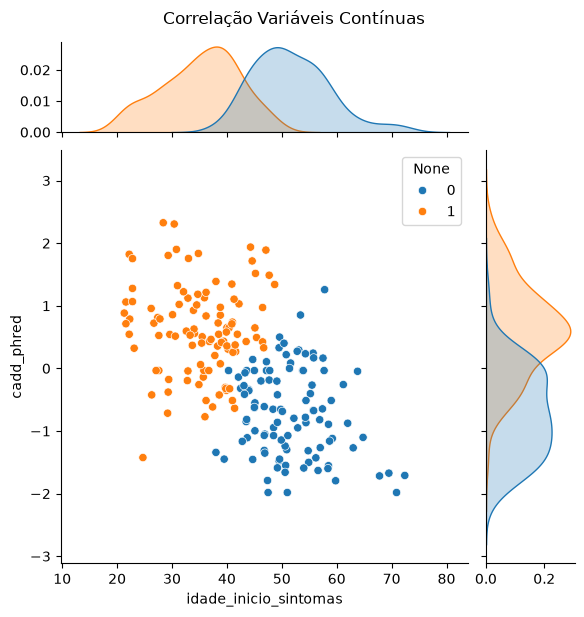

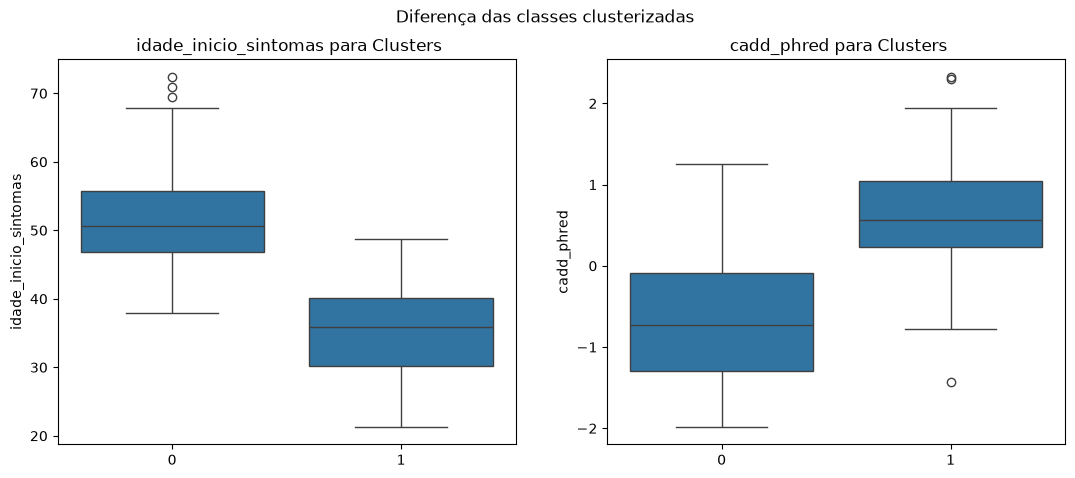


Analisando bivariada 4: idade_inicio_sintomas vs conservacao_phylop
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4097

Silhouette Score -> 0.371
Calinski Harabasz Score -> 156.627
Davies Bouldin Score -> 1.008
Adjusted Rand Score -> 0.14
Adjusted Mutual Info Score -> 0.128


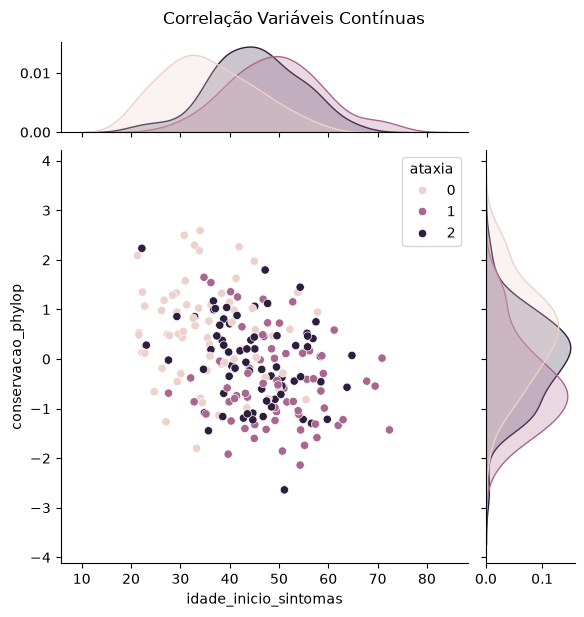

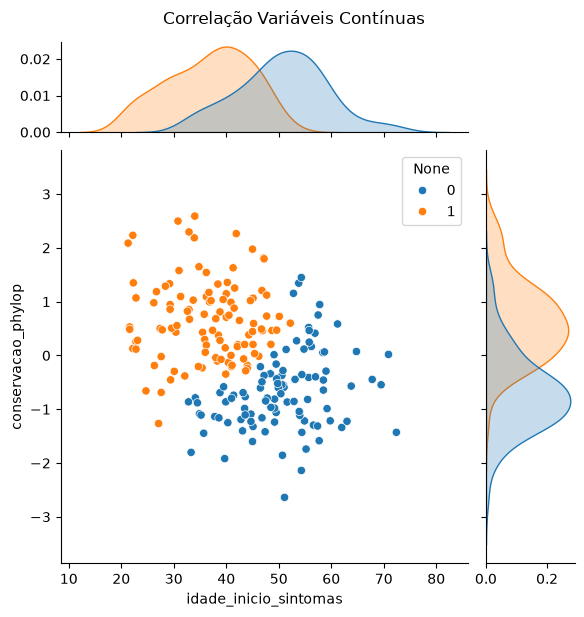

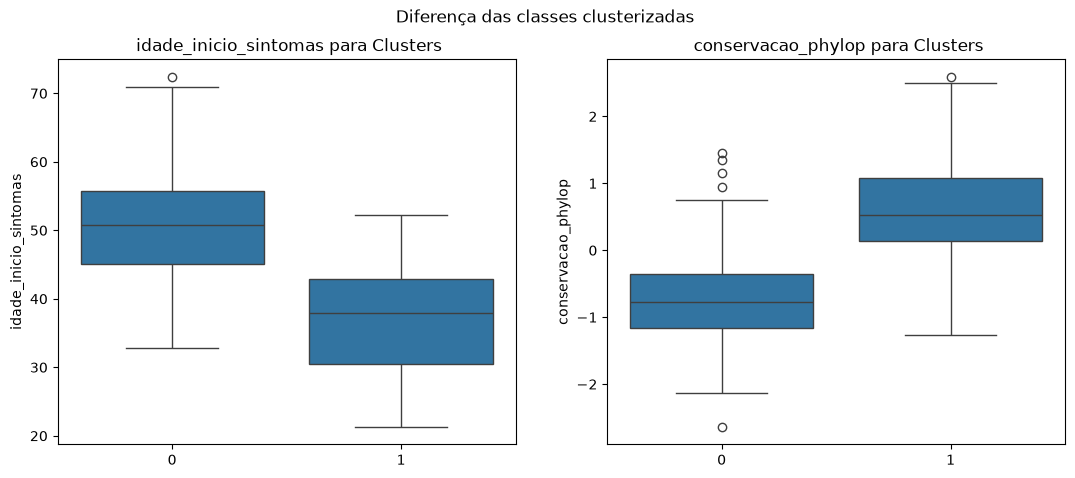


Analisando bivariada 5: idade_inicio_sintomas vs gnomad_af_log
=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 2, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.4375

Silhouette Score -> 0.431
Calinski Harabasz Score -> 179.107
Davies Bouldin Score -> 0.872
Adjusted Rand Score -> 0.07
Adjusted Mutual Info Score -> 0.07


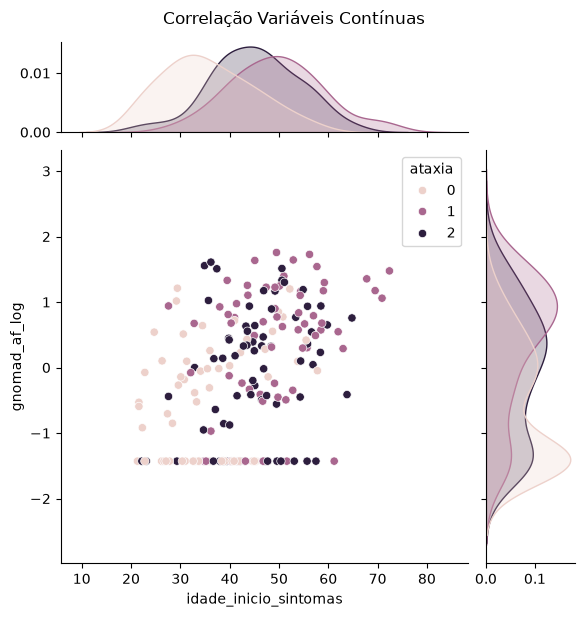

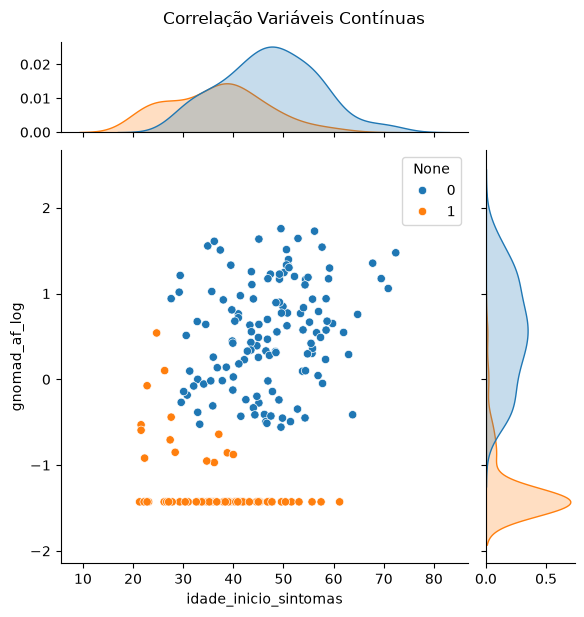

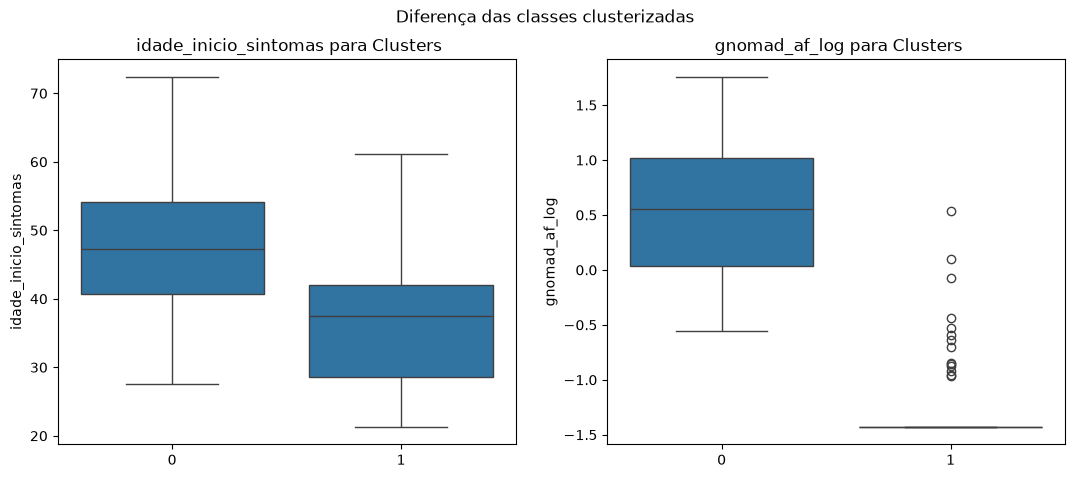

In [33]:
# Analisando os clusters 
print("\n=== CONJUNTO DE VALIDAÇÃO ===")
for k, par in enumerate(bivariadas):
    print(f"\n==========================================")
    print(f"Analisando bivariada {k}: {par[0]} vs {par[1]}")
    print(f"==========================================")
    
    cluster = Clustering(c1=par[0], c2=par[1], df=df_valid, modelo=nome_modelo)
    cluster.cross_validation()

# Analisando métricas validação

In [34]:
# Salvando os dataframes de métricas de avaliação de clustering para cada algoritmo

# K-means
local = f"{caminho_res}df_metricas_repeti_valid_kmeans"
dump(df_metricas_repeti_valid_kmeans, local)
df_metricas_repeti_valid_kmeans = load(local)
df_metricas_repeti_valid_kmeans["algoritmo"] = "kmeans"
print("K-means")
display(df_metricas_repeti_valid_kmeans.head())

# DBSCAN
local = f"{caminho_res}df_metricas_repeti_valid_dbscan"
dump(df_metricas_repeti_valid_dbscan, local)
df_metricas_repeti_valid_dbscan = load(local)
df_metricas_repeti_valid_dbscan["algoritmo"] = "dbscan"
print("DBSCAN")
display(df_metricas_repeti_valid_dbscan.head())

# Agrupamento Hierárquico (Agglomerative)
local = f"{caminho_res}df_metricas_repeti_valid_agg"
dump(df_metricas_repeti_valid_agg, local)
df_metricas_repeti_valid_agg = load(local)
df_metricas_repeti_valid_agg["algoritmo"] = "agg"
print("Agglomerative")
display(df_metricas_repeti_valid_agg.head())

K-means


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.53,359.117,0.682,0.124,0.114,kmeans
1,0.53,359.117,0.682,0.124,0.114,kmeans
2,0.53,359.117,0.682,0.124,0.114,kmeans
3,0.53,359.117,0.682,0.124,0.114,kmeans
4,0.53,359.117,0.682,0.124,0.114,kmeans


DBSCAN


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.142,3.187,4.46,-0.001,-0.003,dbscan
1,0.142,3.187,4.46,-0.001,-0.003,dbscan
2,0.142,3.187,4.46,-0.001,-0.003,dbscan
3,0.142,3.187,4.46,-0.001,-0.003,dbscan
4,0.142,3.187,4.46,-0.001,-0.003,dbscan


Agglomerative


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.513,330.671,0.681,0.13,0.128,agg
1,0.513,330.671,0.681,0.13,0.128,agg
2,0.513,330.671,0.681,0.13,0.128,agg
3,0.513,330.671,0.681,0.13,0.128,agg
4,0.513,330.671,0.681,0.13,0.128,agg


In [35]:
def editar_df(df: pd.DataFrame, modelo: str) -> pd.DataFrame:
    """
    Função para editar o dataframe de métricas de avaliação de clustering
    para cada algoritmo, de forma a facilitar a análise comparativa entre
    eles.
        Parametros:
        -----------
            df: pd.DataFrame
                Dataframe de métricas de avaliação de clustering para
                cada algoritmo.
            modelo: str
                Nome do algoritmo de clustering.
        Retorna:
            pd.DataFrame
    """
    colunas = {0: "valores", "index": "metricas"}
    retorno = (
        df.select_dtypes(include="number")
        .median()
        .to_frame()
        .reset_index()
        .rename(columns=colunas)
        .assign(modelo=modelo)
    )
    return retorno

In [36]:
# Agrupando os resultados das métricas de avaliação de clustering para os três algoritmos e calculando a mediana das métricas
df_metricas = pd.concat(
    (
        editar_df(df=df_metricas_repeti_valid_kmeans, modelo="K-means"),
        editar_df(df=df_metricas_repeti_valid_dbscan, modelo="DBSCAN"),
        editar_df(df=df_metricas_repeti_valid_agg, modelo="Agglomerative"),
    )
)
df_metricas

,metricas,valores,modelo
0,Silhouette,0.530,K-means
1,Calinski Harabasz,359.117,K-means
2,Davies Bouldin,0.682,K-means
3,Adjusted Rand,0.124,K-means
4,Adjusted Mutual Info,0.114,K-means
0,Silhouette,0.142,DBSCAN
1,Calinski Harabasz,3.187,DBSCAN
2,Davies Bouldin,4.460,DBSCAN
3,Adjusted Rand,-0.001,DBSCAN
4,Adjusted Mutual Info,-0.003,DBSCAN


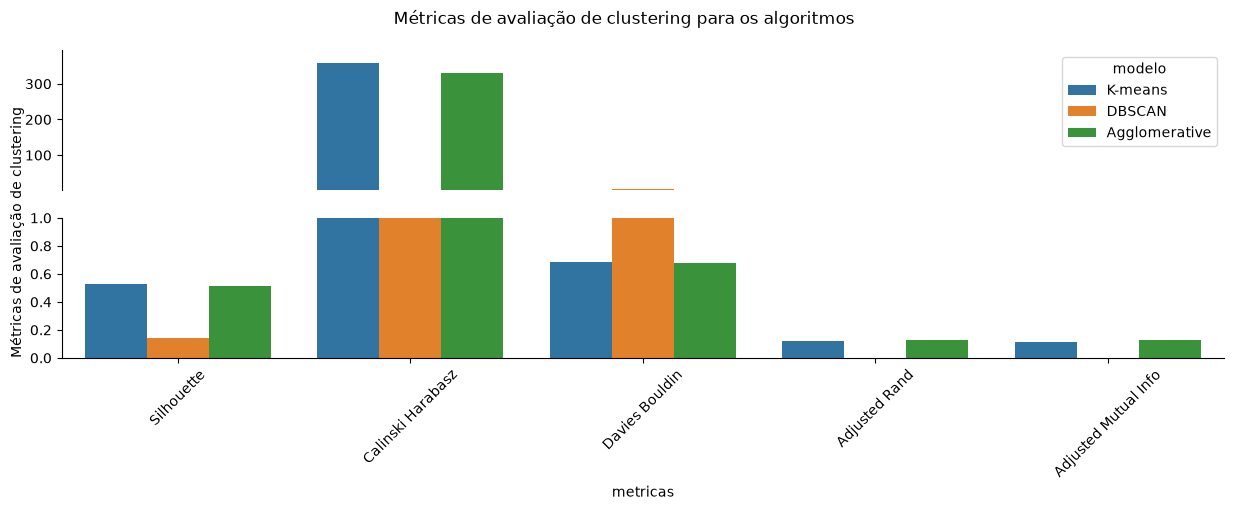

In [37]:
# Grafico comparativo das métricas de avaliação de clustering para os algoritmos (a Calinski-Harabasz tem escala bem maior, por isso fica no painel de cima)
ch = df_metricas.loc[df_metricas["metricas"] == "Calinski Harabasz", "valores"]

fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para os algoritmos")
p = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[0])
p.set_ylim(max(ch.min() * 0.8, 0), ch.max() * 1.1)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

q = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[1])
q.set_ylim(0, 1)
q.tick_params(axis="x", rotation=45)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

# Testes

__Teste Qui-Quadrado de Aderência/Independência__:
- Teste de Proporções dos Clusters: Avalia se a distribuição de frequência de pontos por cluster é idêntica entre treino (715) e teste (103).

__Adjusted Rand Index__:
- Avaliação da Estrutura de Rotulagem (Cross-Prediction ou Teste de Permutação): Avalia se o modelo fitado no treino atribui aos dados de teste os mesmos rótulos que um modelo fitado diretamente no teste atribuiria.

|Hipótese|Interpretação|
|-|-|
|H0 - Hipótese Nula|A distribuição de clusters no teste é igual à do treino. O modelo generalizou bem.|
|H1 - Hipótese Alternativa|A distribuição de clusters no teste é diferente da do treino. Houve data drift ou mudança de padrão.|

## K-means

In [38]:
# Testando os modelos de clustering via K-means
# Os melhores hiperparâmetros de cada bivariada vêm do cross_validation no treino
resultados = {}
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
    cluster.cross_validation(print_metricas=False)
    resultados[f"K-means: {i}/{j}"] = cluster.testar_modelo(
        best_param=cluster.best_params,
        df_test=df_test,
    )

cadd_phred gnomad_af_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação (Treino): 
[54.02097902 48.97902098]
Frequências Observadas na Validação:
       [55 48]
--------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.0373
p-valor:                        0.8468
--------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
--------------------------------------------------
Adjusted Rand Index (ARI) entre modelo de Treino e modelo da Validação: 1.0000 (ARI próximo de 1.0 indica que a partição geométrica gerada é virtualmente idêntica)
cadd_phred conservacao_phylop ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na

## DBSCAN

In [39]:
# Testando os modelos de clustering via DBSCAN
# Os melhores hiperparâmetros de cada bivariada vêm do cross_validation no treino
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="dbscan")
    cluster.cross_validation(print_metricas=False)
    resultados[f"DBSCAN: {i}/{j}"] = cluster.testar_modelo(
        best_param=cluster.best_params,
        df_test=df_test,
    )

cadd_phred gnomad_af_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[0 1]
Frequências Esperadas na Validação:     
[78.65 24.35]
Frequências Observadas na Validação:    
[82 21]
-------------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.6020
p-valor:                        0.4378
-------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters
na validação É IGUAL à do treino (p > 0.05).
-------------------------------------------------------
Adjusted Rand Index (ARI) entre predição e DBSCAN direto na Validação: 0.4158
cadd_phred conservacao_phylop ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[-1  0]
Frequências Esperadas n

## Agrupamento Hierarquico

In [40]:
# Testando os modelos de clustering via Agrupamento Hierarquico
# Os melhores hiperparâmetros de cada bivariada vêm do cross_validation no treino
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="agglomerative")
    cluster.cross_validation(print_metricas=False)
    resultados[f"Agg: {i}/{j}"] = cluster.testar_modelo(
        best_param=cluster.best_params,
        df_test=df_test,
    )

cadd_phred gnomad_af_log ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[61.66 41.34]
Frequências Observadas na Validação:  
[57 46]
------------------------------------------------------------
Estatística Qui-Quadrado (χ²): 0.8759
p-valor:                        0.3493
------------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
------------------------------------------------------------
Adjusted Rand Index (ARI) entre projeção e agrupamento direto: 0.7106
cadd_phred conservacao_phylop ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esper

## Resultado Final

In [41]:
for chave, valor in resultados.items():
    print(f"{chave} -> {valor}")

K-means: cadd_phred/gnomad_af_log -> True
K-means: cadd_phred/conservacao_phylop -> True
K-means: conservacao_phylop/gnomad_af_log -> True
K-means: idade_inicio_sintomas/cadd_phred -> True
K-means: idade_inicio_sintomas/conservacao_phylop -> True
K-means: idade_inicio_sintomas/gnomad_af_log -> True
DBSCAN: cadd_phred/gnomad_af_log -> True
DBSCAN: cadd_phred/conservacao_phylop -> True
DBSCAN: conservacao_phylop/gnomad_af_log -> True
DBSCAN: idade_inicio_sintomas/cadd_phred -> True
DBSCAN: idade_inicio_sintomas/conservacao_phylop -> True
DBSCAN: idade_inicio_sintomas/gnomad_af_log -> True
Agg: cadd_phred/gnomad_af_log -> True
Agg: cadd_phred/conservacao_phylop -> False
Agg: conservacao_phylop/gnomad_af_log -> True
Agg: idade_inicio_sintomas/cadd_phred -> True
Agg: idade_inicio_sintomas/conservacao_phylop -> False
Agg: idade_inicio_sintomas/gnomad_af_log -> True
